# SH 2-71 investigation

We start by defining some constants and importing the necessary libraries.

In [1]:
from astropy.coordinates import SkyCoord
import lightkurve as lk
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import astropy.units as u
%matplotlib inline

coords = SkyCoord("285.5 +2.156388", unit=("deg", "deg"))

search: lk.SearchResult = lk.search_tesscut(coords)

d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
print(search)

SearchResult containing 2 data products.

 #     mission     year  author exptime   target_name   distance
                                   s                     arcsec 
--- -------------- ---- ------- ------- --------------- --------
  0 TESS Sector 54 2022 TESScut     475 285.5, 2.156388      0.0
  1 TESS Sector 80 2024 TESScut     158 285.5, 2.156388      0.0


In [3]:
if len(search) == 0:
    raise ValueError("No TESS cutouts found for the given coordinates.")

files = search.download_all(cutout_size=(20, 20), download_dir="./fitsdata", quality_bitmask="default")

# lets analyze each file, if we iterate over the SearchResult object we get a Table with metadata for each file
if files is None or len(files) < 2:
    raise ValueError("No valid files were downloaded. Please check the search results.")

aristoteles: lk.TessTargetPixelFile = files[0]
bethesda: lk.TessTargetPixelFile = files[1]

if not isinstance(aristoteles, lk.TessTargetPixelFile) and not isinstance(bethesda, lk.TessTargetPixelFile):
    raise TypeError("One or both of the files are not of type TessTargetPixelFile.")

PARAMETERS SECTION

We need to understand four parameters:

TIMEDEL:
Cadence/time resolution of the final data, expressed in days.
This represents approximately how much time separates one stored flux measurement
from the next one.

This is the most useful parameter for defining the sampling cadence of the
light curve.

FRAMETIM:
Frame time in seconds.
This is the total duration associated with one individual detector frame.

FRAMETIM includes both:
    - INT_TIME: photon accumulation time
    - READTIME: detector readout time

Therefore:

    FRAMETIM = INT_TIME + READTIME

We do not directly analyze these individual frames because several frames are
combined to produce each point in the final light curve.

INT_TIME:
Integration time in seconds for ONE individual frame.
This is the time during which the detector is actually accumulating photons.

It is NOT the time resolution of the final light curve.

NUM_FRM:
Number of individual frames used to construct one timestamp/cadence.

Therefore:

    nominal cadence ≈ FRAMETIM × NUM_FRM

while:

    total possible photon integration = INT_TIME × NUM_FRM

For these TESS products, onboard cosmic-ray mitigation removes the highest and
lowest value in every group of 10 frames. Therefore, effectively 8 out of every
10 frames contribute to the final flux.

Thus:

    effective exposure ≈ INT_TIME × NUM_FRM × 0.8

TIMEDEL should approximately correspond to the cadence:

    cadence_seconds = TIMEDEL × 86400

In [4]:
a_header = aristoteles.get_header(ext=1)

a_timedel = a_header["TIMEDEL"]
a_frametim = a_header["FRAMETIM"]
a_num_frm = a_header["NUM_FRM"]
a_int_time = a_header["INT_TIME"]


b_header = bethesda.get_header(ext=1)

b_timedel = b_header["TIMEDEL"]
b_frametim = b_header["FRAMETIM"]
b_num_frm = b_header["NUM_FRM"]
b_int_time = b_header["INT_TIME"]


print("Aristoteles parameters:")
print(f"TIMEDEL: {a_timedel} days")
print(f"FRAMETIM: {a_frametim} seconds")
print(f"NUM_FRM: {a_num_frm}")
print(f"INT_TIME: {a_int_time} seconds")

print("\nBethesda parameters:")
print(f"TIMEDEL: {b_timedel} days")
print(f"FRAMETIM: {b_frametim} seconds")
print(f"NUM_FRM: {b_num_frm}")
print(f"INT_TIME: {b_int_time} seconds")

Aristoteles parameters:
TIMEDEL: 0.006944444444444444 days
FRAMETIM: 2.0 seconds
NUM_FRM: 300
INT_TIME: 1.98 seconds

Bethesda parameters:
TIMEDEL: 0.0023148148148148 days
FRAMETIM: 2.0 seconds
NUM_FRM: 100
INT_TIME: 1.98 seconds


In [5]:
# Nominal cadence
a_cadence_time = a_frametim * a_num_frm
b_cadence_time = b_frametim * b_num_frm

# Total integration before cosmic ray mitigation
a_raw_integration = a_int_time * a_num_frm
b_raw_integration = b_int_time * b_num_frm

# Effective exposure after cosmic ray mitigation
a_exposure_time = a_raw_integration * 0.8
b_exposure_time = b_raw_integration * 0.8


print("Aristoteles:")
print(f"Cadence: {a_cadence_time} s")
print(f"Raw integration: {a_raw_integration} s")
print(f"Effective exposure: {a_exposure_time} s")

print("\nBethesda:")
print(f"Cadence: {b_cadence_time} s")
print(f"Raw integration: {b_raw_integration} s")
print(f"Effective exposure: {b_exposure_time} s")

Aristoteles:
Cadence: 600.0 s
Raw integration: 594.0 s
Effective exposure: 475.20000000000005 s

Bethesda:
Cadence: 200.0 s
Raw integration: 198.0 s
Effective exposure: 158.4 s


## Mask definition


<Axes: title={'center': 'Target ID: 285.5, 2.156388, Cadence: 0'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>

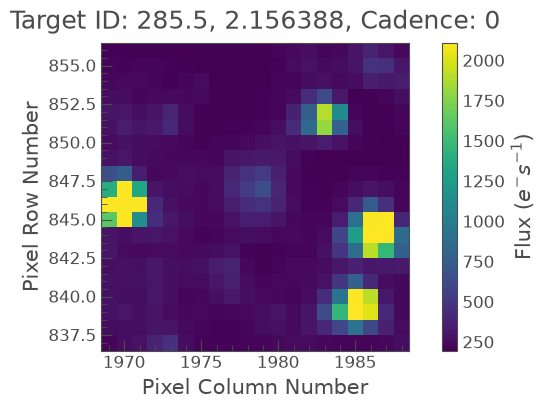

In [6]:
# to decide the pixels we will cover we take in count the size of the PN
# which is 2.1 arcmin, so having that tess pixels are 21 arcsec we need to cover 6x6 pixels

aper_new = np.zeros(aristoteles.shape[1:], dtype=bool)
aper_new[8:14, 8:13] = True

aristoteles.plot()


In [7]:
aristoteles_mean = aristoteles.flux.mean(axis=(0)).value
bethesda_mean = bethesda.flux.mean(axis=(0)).value

ari_mean_masked = np.ma.masked_array(aristoteles_mean, mask=~aper_new)
bethesda_mean_masked = np.ma.masked_array(bethesda_mean, mask=~aper_new)

print(f"Aristoteles mean flux (masked): {ari_mean_masked.mean()}")
print(f" Bethesda mean flux (masked): {bethesda_mean_masked.mean()}")

Aristoteles mean flux (masked): 761.621484375
 Bethesda mean flux (masked): 1739.7837239583334


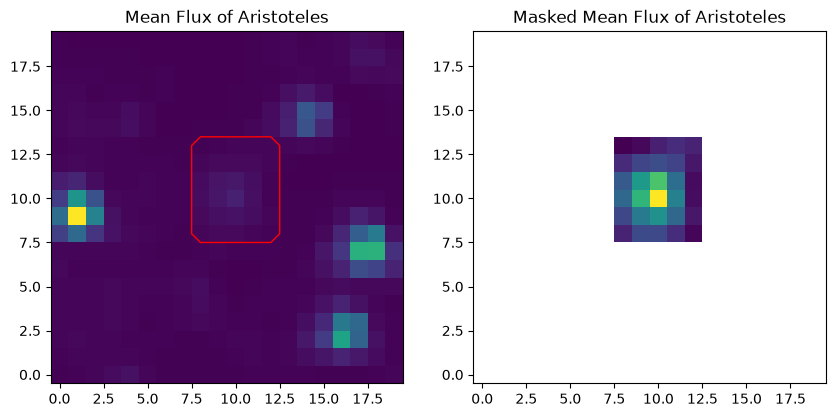

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(aristoteles_mean, origin='lower', cmap='viridis')
ax[0].set_title('Mean Flux of Aristoteles')
ax[0].contour(aper_new, colors='red', linewidths=1)

ax[1].imshow(ari_mean_masked, origin='lower', cmap='viridis')
ax[1].set_title('Masked Mean Flux of Aristoteles')

plt.show()

## LightCurves definitions and initialization
First we start with simple light curves, with sap taking the entire aperture and some with only the aperture we use for sh 2 71

In [9]:
lc_aristoteles_default = aristoteles.to_lightcurve()
lc_bethesda_default = bethesda.to_lightcurve()

In [10]:
if aristoteles is None or bethesda is None:
    raise ValueError("One or both of the files are None. Please check the downloaded files.")

if not isinstance(aristoteles, lk.TessTargetPixelFile) or not isinstance(bethesda, lk.TessTargetPixelFile):
    raise TypeError("One or both of the files are not of type TessTargetPixelFile.")

lc_aristoteles_sum = aristoteles.to_lightcurve(method='sap', flux_method='sum')
lc_aristoteles_mean = aristoteles.to_lightcurve(method='sap', flux_method='mean')
lc_aristoteles_sap_sum = aristoteles.to_lightcurve(method='sap', aperture_mask=aper_new, flux_method='sum')
lc_aristoteles_sap_mean = aristoteles.to_lightcurve(method='sap', aperture_mask=aper_new, flux_method='mean')

lc_bethesda_sum = bethesda.to_lightcurve(method='sap', flux_method='sum')
lc_bethesda_mean = bethesda.to_lightcurve(method='sap', flux_method='mean')
lc_bethesda_sap_sum = bethesda.to_lightcurve(method='sap', aperture_mask=aper_new, flux_method='sum')
lc_bethesda_sap_mean = bethesda.to_lightcurve(method='sap', aperture_mask=aper_new, flux_method='mean')


if not isinstance(lc_aristoteles_sap_mean, lk.LightCurve) or not isinstance(lc_bethesda_sap_mean, lk.LightCurve):
    raise TypeError("One or both of the light curves are not of type LightCurve.")

## background noise removal

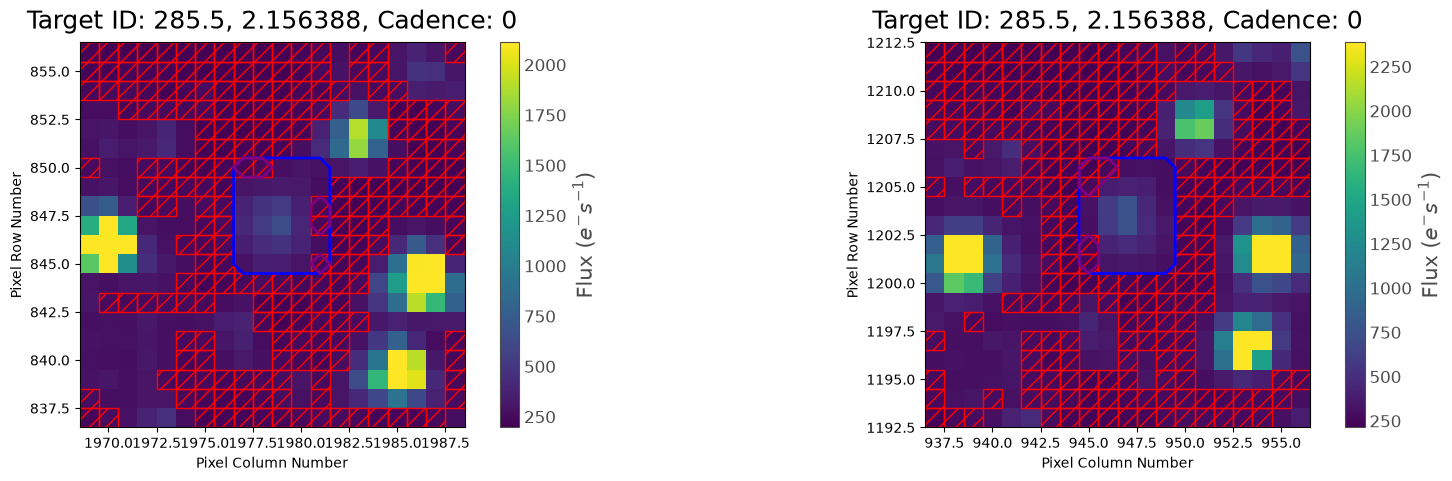

In [11]:
aristoteles_bg_mask = ~aristoteles.create_threshold_mask(threshold=0.1, reference_pixel=None)
bethesda_bg_mask = ~bethesda.create_threshold_mask(threshold=0.1, reference_pixel=None)

fig, ax = plt.subplots(1, 2, figsize=(20, 5))

aristoteles.plot(ax=ax[0], aperture_mask=aristoteles_bg_mask, mask_color='red', frame=0)
bethesda.plot(ax=ax[1], aperture_mask=bethesda_bg_mask, mask_color='red', frame=0)

X1, Y1 = np.meshgrid(
    np.arange(aristoteles.shape[2]) + aristoteles.column,
    np.arange(aristoteles.shape[1]) + aristoteles.row
)
X2, Y2 = np.meshgrid(
    np.arange(bethesda.shape[2]) + bethesda.column,
    np.arange(bethesda.shape[1]) + bethesda.row
)
ax[0].contour(X1, Y1, aper_new, levels=[0.5], colors='blue', linewidths=2)
ax[1].contour(X2, Y2, aper_new, levels=[0.5], colors='blue', linewidths=2)

aristoteles_overlap_mask = np.logical_and(aristoteles_bg_mask, aper_new)
bethesda_overlap_mask = np.logical_and(bethesda_bg_mask, aper_new)
ax[0].contour(X1, Y1, aristoteles_overlap_mask, levels=[0.5], colors='purple', linewidths=2)
ax[1].contour(X2, Y2, bethesda_overlap_mask, levels=[0.5], colors='purple', linewidths=2)

plt.show()

In [12]:
# now for each cadence we need to take the mean of the pixels in the bg mask
aristoteles_bg_mask_mean = np.mean(aristoteles.flux[:, aristoteles_bg_mask], axis=1)
bethesda_bg_mask_mean = np.mean(bethesda.flux[:, bethesda_bg_mask], axis=1)

print(aristoteles_bg_mask_mean.shape)
print(aristoteles_bg_mask_mean)

print(bethesda_bg_mask_mean.shape)
print(bethesda_bg_mask_mean)

print("Means of different light curves:")
print(f"Aristoteles SAP Mean: {np.mean(lc_aristoteles_sap_mean.flux.value)}")

(2781,)
[229.81783 230.00288 230.11006 ... 226.23935 226.3678  226.48839] electron / s
(10399,)
[252.2667  252.13182 252.02165 ... 253.26878 253.07164 253.03186] electron / s
Means of different light curves:
Aristoteles SAP Mean: 761.6212768554688


In [13]:
lc_aristoteles_sap_bg_corrected = lc_aristoteles_sap_mean.copy()
lc_aristoteles_sap_bg_corrected.flux = lc_aristoteles_sap_mean.flux - aristoteles_bg_mask_mean

lc_bethesda_sap_bg_corrected = lc_bethesda_sap_mean.copy()
lc_bethesda_sap_bg_corrected.flux = lc_bethesda_sap_mean.flux - bethesda_bg_mask_mean

Now that we have the bg noise we remove that noise from the cbvs corrected light curves, we should subtract for each cadence the meaned background flux from the cbvs corrected flux

Text(0, 0.5, 'Flux (Background Subtracted)')

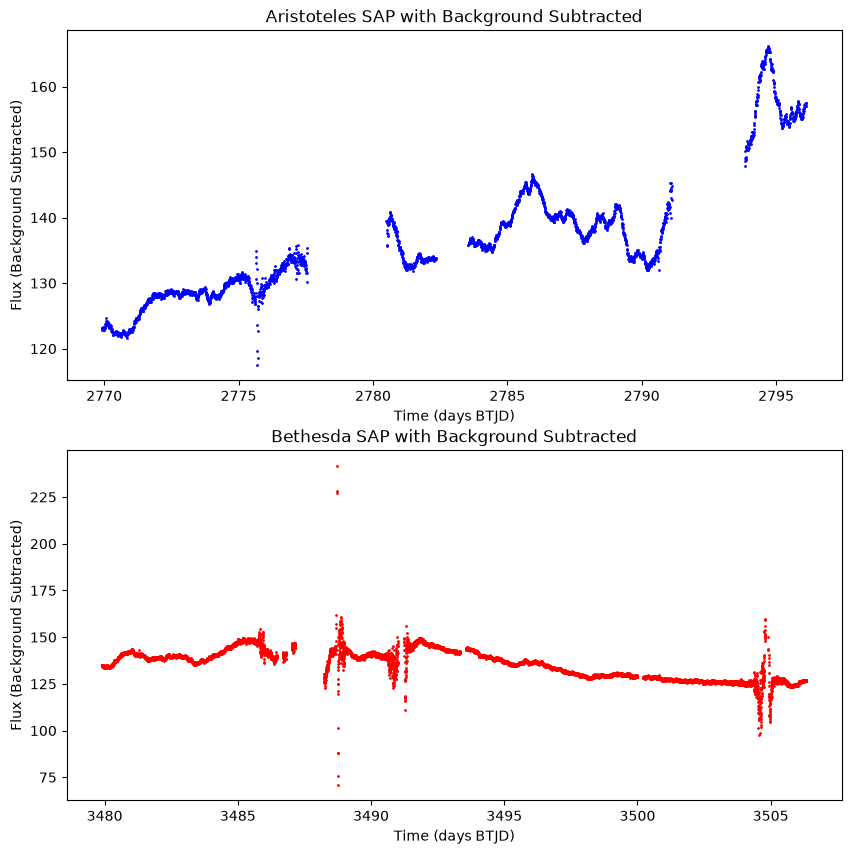

In [14]:
lc_aristoteles_sap_bg = lc_aristoteles_sap_mean.copy()
lc_aristoteles_sap_bg.flux = lc_aristoteles_sap_mean.flux - aristoteles_bg_mask_mean
lc_bethesda_sap_bg = lc_bethesda_sap_mean.copy()
lc_bethesda_sap_bg.flux = lc_bethesda_sap_mean.flux - bethesda_bg_mask_mean

fig, ax = plt.subplots(2, 1, figsize=(10, 10))
ax[0].scatter(lc_aristoteles_sap_bg.time.value, lc_aristoteles_sap_bg.flux.value, color='blue', s=1)
ax[0].set_title('Aristoteles SAP with Background Subtracted')
ax[0].set_xlabel('Time (days BTJD)')
ax[0].set_ylabel('Flux (Background Subtracted)')

ax[1].scatter(lc_bethesda_sap_bg.time.value, lc_bethesda_sap_bg.flux.value, color='red', s=1)
ax[1].set_title('Bethesda SAP with Background Subtracted')
ax[1].set_xlabel('Time (days BTJD)')
ax[1].set_ylabel('Flux (Background Subtracted)')

So, at this point we have the light curve `lc_aristoteles_sap_bg` and `lc_bethesda_sap_bg` which are the light curves where we applied a sap using the nebula aperture mask then we subtracted the meaned background flux (of each cadence)

## correctors
Here we apply some correctors to the light curves, first with CBVs, currently we are working with the meaned light curve over the aperture mask defined above, but we can also use the sumed light curve, or the entire aperture light curve.

Also we use SingleScale because we want to take in count every single CBV and maintain the long term trends

In [21]:
aristoteles_corr_cbvs = lc_aristoteles_sap_bg.to_corrector(method='cbv', interpolate_cbvs=True, extrapolate_cbvs=True)
bethesda_corr_cbvs = lc_bethesda_sap_bg.to_corrector(method='cbv', interpolate_cbvs=True, extrapolate_cbvs=True)

Aristoteles CBVS Corrector (5): [TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType : SingleScale, nCBVS : 16, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType.Band: MultiScale.1, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType.Band: MultiScale.2, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType.Band: MultiScale.3, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType : Spike, nCBVS : 8]
Bethesda CBVS Corrector (5): [TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType : SingleScale, nCBVS : 16, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType.Band: MultiScale.1, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType.Band: MultiScale.2, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType.Band: MultiScale.3, nCBVs : 7, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType : Spike, nCBVS : 8]


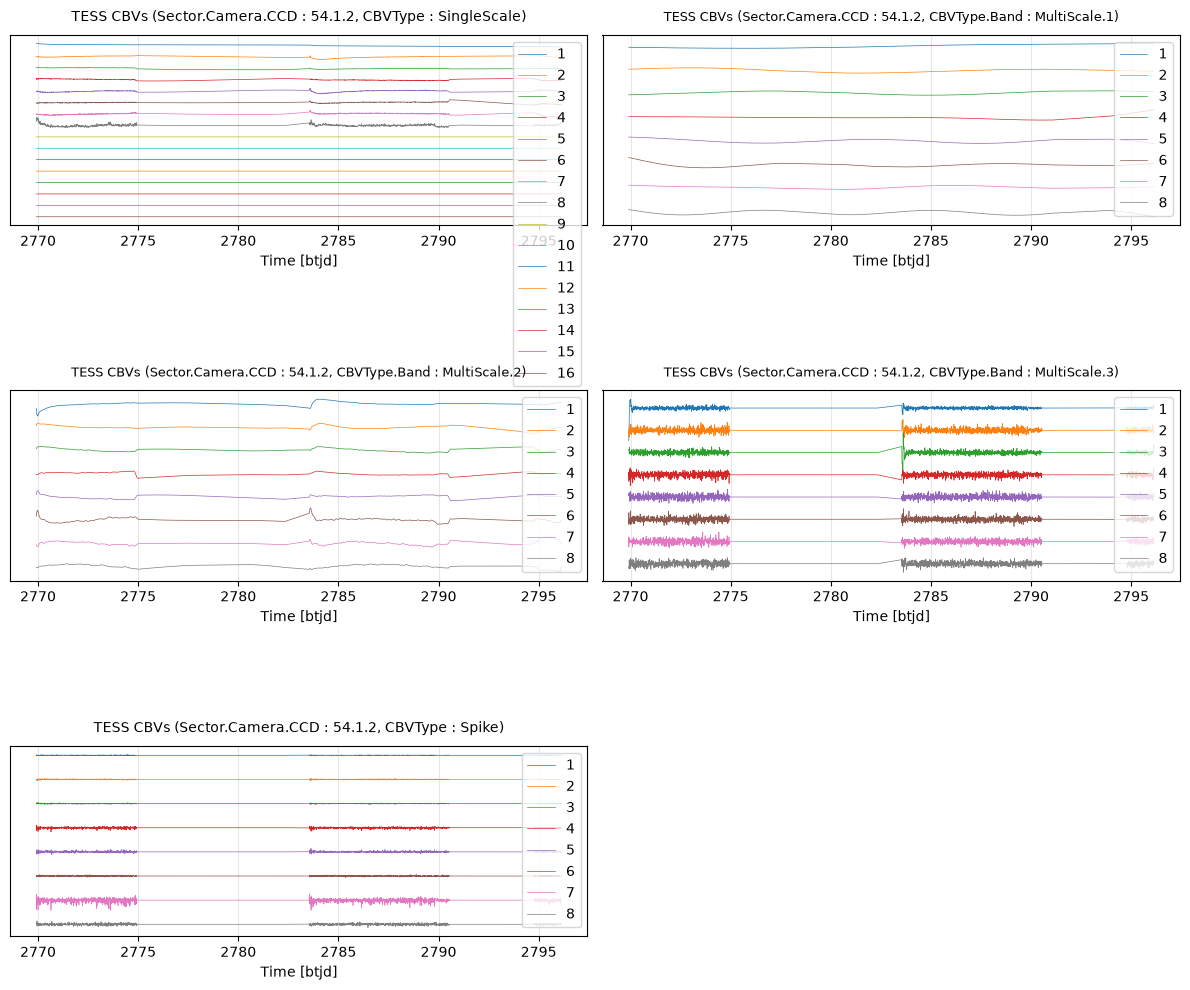

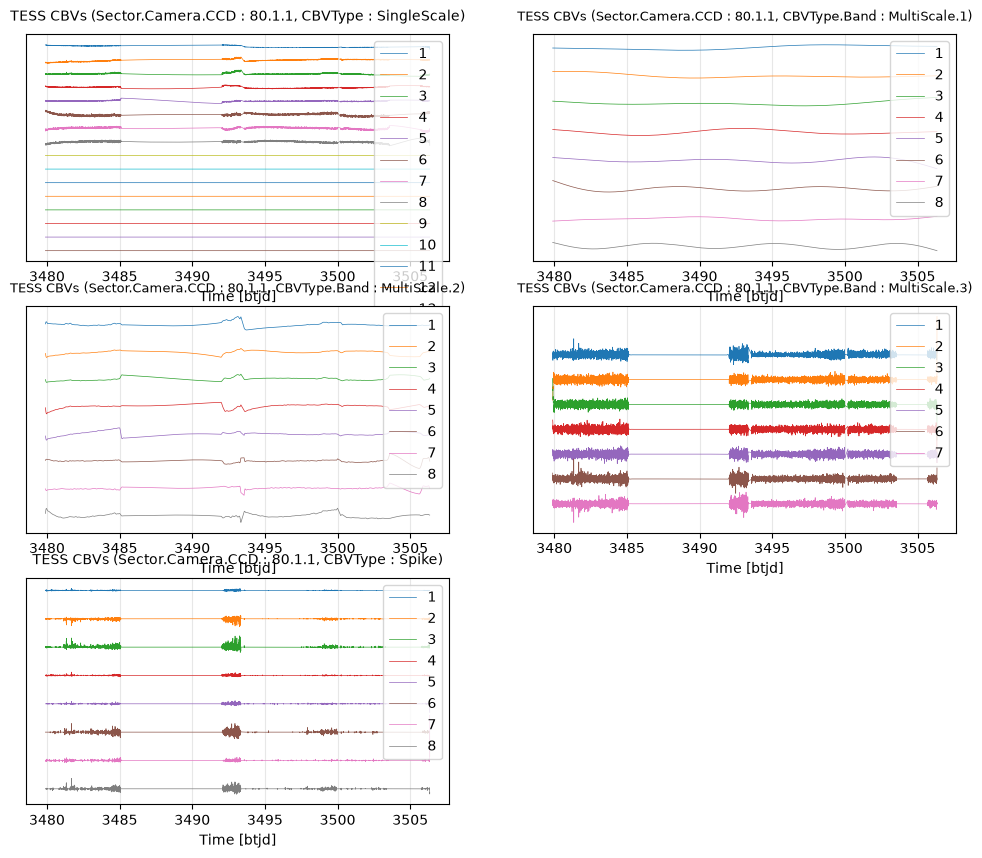

In [22]:
print(f"Aristoteles CBVS Corrector ({len(aristoteles_corr_cbvs.cbvs)}):", aristoteles_corr_cbvs.cbvs)
print(f"Bethesda CBVS Corrector ({len(bethesda_corr_cbvs.cbvs)}):", bethesda_corr_cbvs.cbvs)

fig_ari, axa = plt.subplots(3, 2, figsize=(12, 10))
axa = axa.flatten() 

for i, cbv in enumerate(aristoteles_corr_cbvs.cbvs):
    cbv.plot(ax=axa[i])
    axa[i].legend(loc='upper right')

axa[5].set_visible(False)

fig_ari.tight_layout()


fig_bet, axb = plt.subplots(3, 2, figsize=(12, 10))
axb = axb.flatten()

for i, cbv in enumerate(bethesda_corr_cbvs.cbvs):
    cbv.plot(ax=axb[i])
    axb[i].legend(loc='upper right')

axb[5].set_visible(False)

plt.show()

In [24]:
lc_aristoteles_ss_cbvs = aristoteles_corr_cbvs.correct(cbv_type=['SingleScale'], cbv_indices=[np.arange(1, 8)])
lc_bethesda_ss_cbvs = bethesda_corr_cbvs.correct(cbv_type=['SingleScale'], cbv_indices=[np.arange(1, 8)])

Optimized Over-fitting metric: 0.999983899040847
Optimized Under-fitting metric: 0.6496146324271411
Optimized Alpha: 9.803e+03
Optimized Over-fitting metric: 0.8725858644776217
Optimized Under-fitting metric: 0.9917799564406418
Optimized Alpha: 1.240e-02


In [25]:
lc_aristoteles_spike_cbvs = aristoteles_corr_cbvs.correct(cbv_type=['Spike'], cbv_indices=[np.arange(1, 8)])
lc_bethesda_spike_cbvs = bethesda_corr_cbvs.correct(cbv_type=['Spike'], cbv_indices=[np.arange(1, 8)])

Optimized Over-fitting metric: 0.999957810433412
Optimized Under-fitting metric: 0.6496104337751099
Optimized Alpha: 9.489e+03
Optimized Over-fitting metric: 0.9999944687894244
Optimized Under-fitting metric: 0.5472533390990091
Optimized Alpha: 9.662e+03


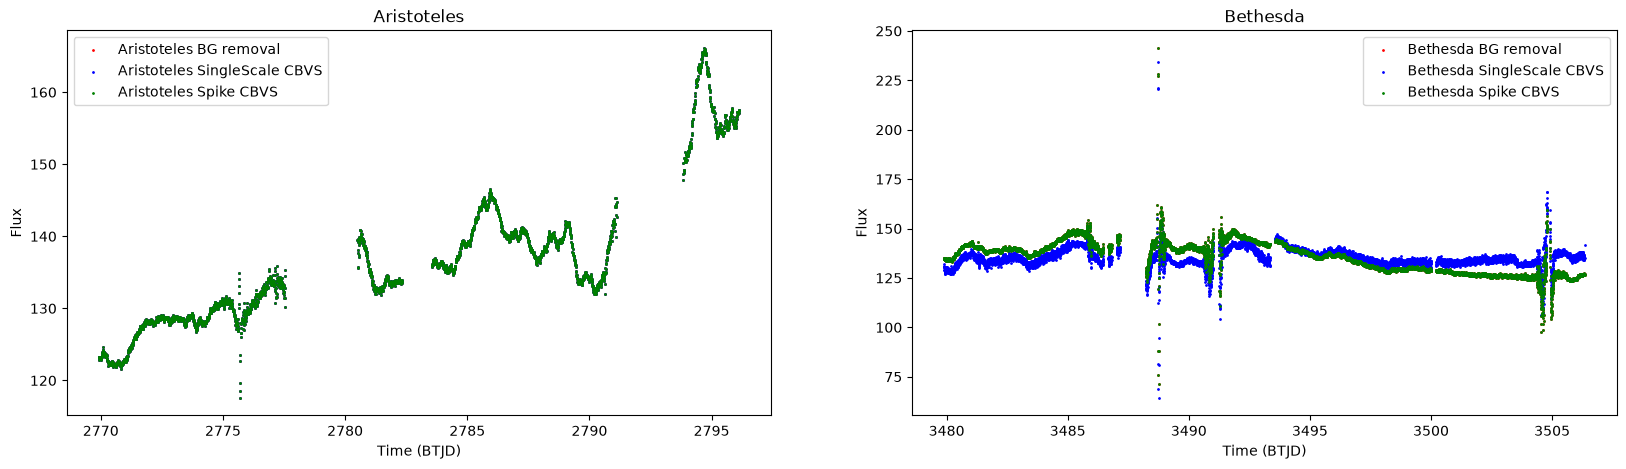

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(20, 5))

ax[0].scatter(lc_aristoteles_sap_bg.time.value, lc_aristoteles_sap_bg.flux.value, color='red', label='Aristoteles BG removal', s=1)
ax[0].scatter(lc_aristoteles_ss_cbvs.time.value, lc_aristoteles_ss_cbvs.flux.value, color='blue', label='Aristoteles SingleScale CBVS', s=1)
ax[0].scatter(lc_aristoteles_spike_cbvs.time.value, lc_aristoteles_spike_cbvs.flux.value, color='green', label='Aristoteles Spike CBVS', s=1)
ax[0].set_xlabel('Time (BTJD)')
ax[0].set_ylabel('Flux')
ax[0].set_title('Aristoteles')
ax[0].legend()

ax[1].scatter(lc_bethesda_sap_bg.time.value, lc_bethesda_sap_bg.flux.value, color='red', label='Bethesda BG removal', s=1)
ax[1].scatter(lc_bethesda_ss_cbvs.time.value, lc_bethesda_ss_cbvs.flux.value, color='blue', label='Bethesda SingleScale CBVS', s=1)
ax[1].scatter(lc_bethesda_spike_cbvs.time.value, lc_bethesda_spike_cbvs.flux.value, color='green', label='Bethesda Spike CBVS', s=1)
ax[1].set_xlabel('Time (BTJD)')
ax[1].set_ylabel('Flux')
ax[1].set_title('Bethesda')
ax[1].legend()



Based on above data the difference is minimal for aristoteles but significant for bethesda, but we still will use single scale and spike just to clean it up a bit more

In [27]:
lc_aristoteles_cbvs = aristoteles_corr_cbvs.correct(cbv_type=['SingleScale', 'Spike'], cbv_indices=[np.arange(1, 8), np.arange(1, 8)])
lc_bethesda_cbvs = bethesda_corr_cbvs.correct(cbv_type=['SingleScale', 'Spike'], cbv_indices=[np.arange(1, 8), np.arange(1, 8)])

Optimized Over-fitting metric: 0.9999521093696017
Optimized Under-fitting metric: 0.6496143627308169
Optimized Alpha: 9.625e+03
Optimized Over-fitting metric: 0.8757533577322879
Optimized Under-fitting metric: 0.9909801492145196
Optimized Alpha: 1.458e-02


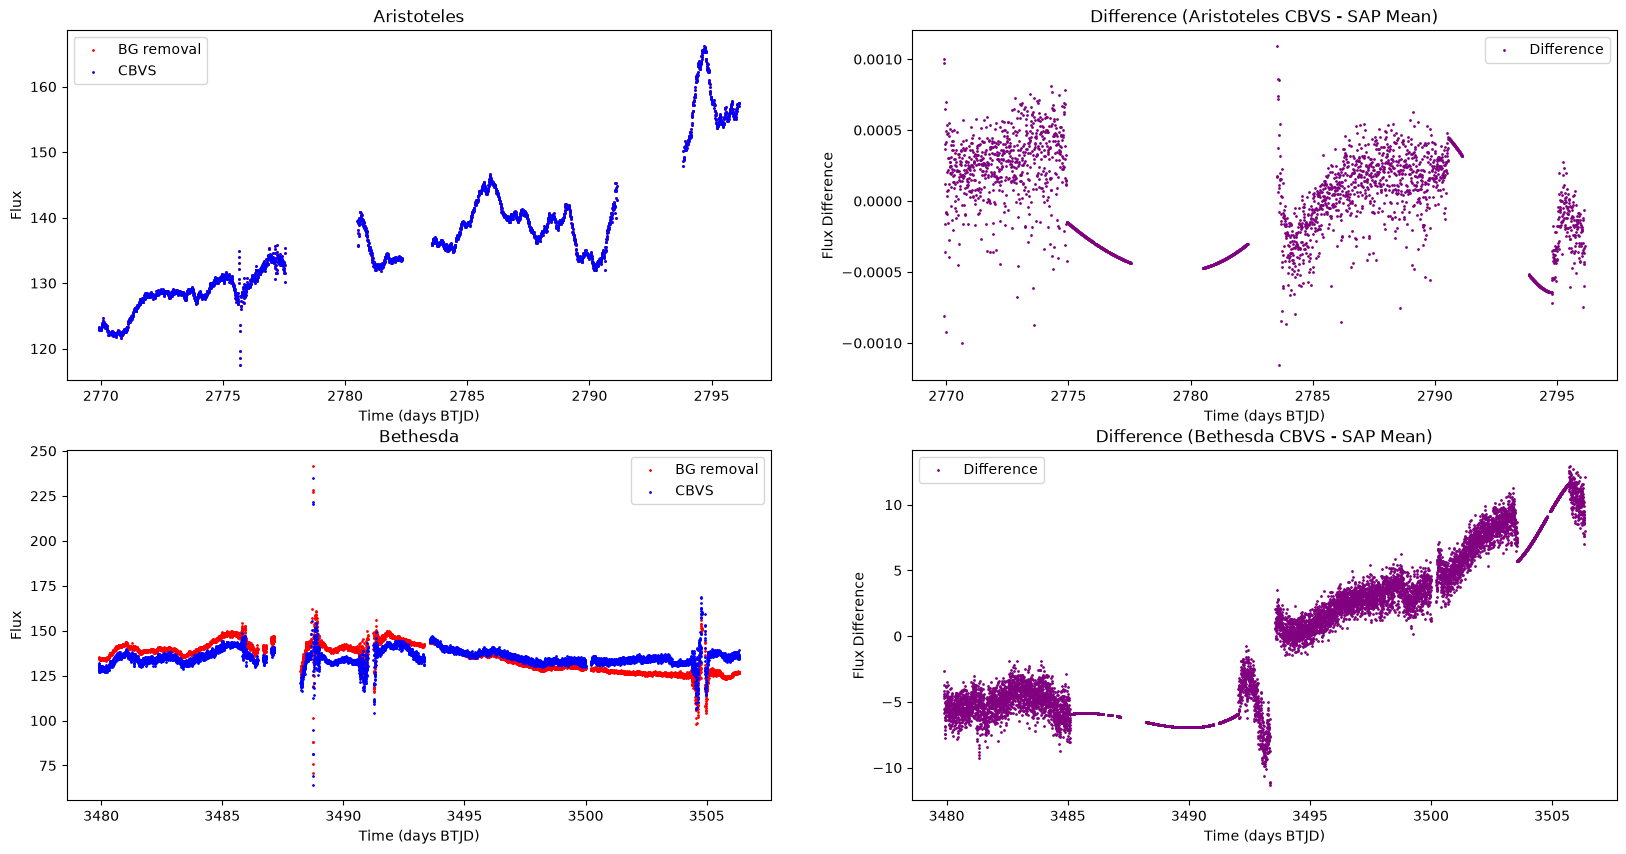

In [28]:
fig, ax = plt.subplots(2, 2, figsize=(20, 10))

# plot for comparison of lcs
ax[0, 0].scatter(lc_aristoteles_sap_bg.time.value, lc_aristoteles_sap_bg.flux.value, color='red', s=1)
ax[0, 0].scatter(lc_aristoteles_cbvs.time.value, lc_aristoteles_cbvs.flux.value, color='blue', s=1)
ax[0, 0].set_title('Aristoteles')
ax[0, 0].set_xlabel('Time (days BTJD)')
ax[0, 0].set_ylabel('Flux')
ax[0, 0].legend(['BG removal', 'CBVS'])

# difference between the two light curves
diff_aristoteles = np.subtract(lc_aristoteles_cbvs.flux.value, lc_aristoteles_sap_bg.flux.value)
ax[0, 1].scatter(lc_aristoteles_cbvs.time.value, diff_aristoteles, color='purple', s=1)
ax[0, 1].set_title('Difference (Aristoteles CBVS - SAP Mean)')
ax[0, 1].set_xlabel('Time (days BTJD)')
ax[0, 1].set_ylabel('Flux Difference')
ax[0, 1].legend(['Difference'])

ax[1, 0].scatter(lc_bethesda_sap_bg.time.value, lc_bethesda_sap_bg.flux.value, color='red', s=1)
ax[1, 0].scatter(lc_bethesda_cbvs.time.value, lc_bethesda_cbvs.flux.value, color='blue', s=1)
ax[1, 0].set_title('Bethesda')
ax[1, 0].set_xlabel('Time (days BTJD)')
ax[1, 0].set_ylabel('Flux')
ax[1, 0].legend(['BG removal', 'CBVS'])

# difference between the two light curves
diff_bethesda = np.subtract(lc_bethesda_cbvs.flux.value, lc_bethesda_sap_bg.flux.value)
ax[1, 1].scatter(lc_bethesda_cbvs.time.value, diff_bethesda, color='purple', s=1)
ax[1, 1].set_title('Difference (Bethesda CBVS - SAP Mean)')
ax[1, 1].set_xlabel('Time (days BTJD)')
ax[1, 1].set_ylabel('Flux Difference')
ax[1, 1].legend(['Difference'])

At this point we have `lc_aristoteles_cbvs` and `lc_bethesda_cbvs` where we applied sap -> bg removal -> cbvs correction

## PLD corrector comparison

In [29]:
aristoteles_pld_corrector = aristoteles.to_corrector(method='pld')
bethesda_pld_corrector = bethesda.to_corrector(method='pld')

In [30]:
lc_aristoteles_pld = aristoteles_pld_corrector.correct(aperture_mask=aristoteles.pipeline_mask, background_aperture_mask=aristoteles_bg_mask)
lc_bethesda_pld = bethesda_pld_corrector.correct(aperture_mask=bethesda.pipeline_mask, background_aperture_mask=bethesda_bg_mask)

d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\astropy\utils\decorators.py:620: LightkurveDeprecationWarning: "aperture_mask" was deprecated in version 2.0 and will be removed in a future version. 
  return function(*args, **kwargs)
d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\astropy\utils\decorators.py:620: LightkurveDeprecationWarning: "aperture_mask" was deprecated in version 2.0 and will be removed in a future version. 
  return function(*args, **kwargs)


array([<Axes: title={'center': 'aperture_mask'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>,
       <Axes: title={'center': 'pld_aperture_mask'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>,
       <Axes: title={'center': 'background_aperture_mask'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>],
      dtype=object)

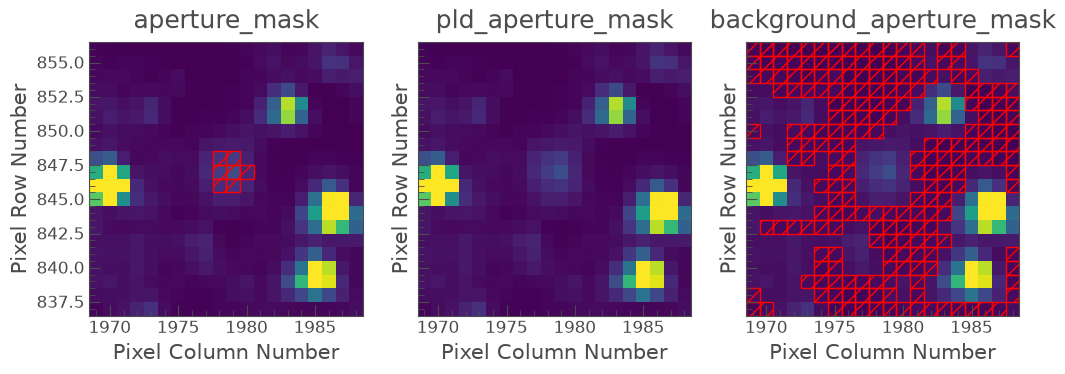

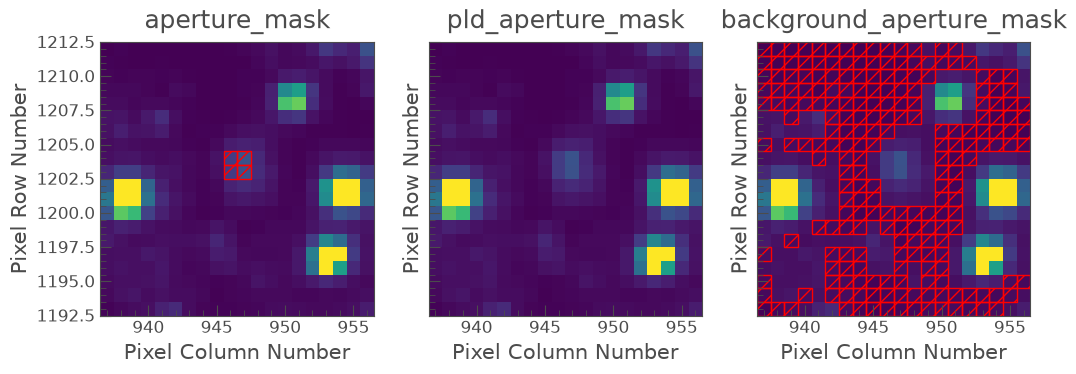

In [31]:
aristoteles_pld_corrector.diagnose_masks()
bethesda_pld_corrector.diagnose_masks()

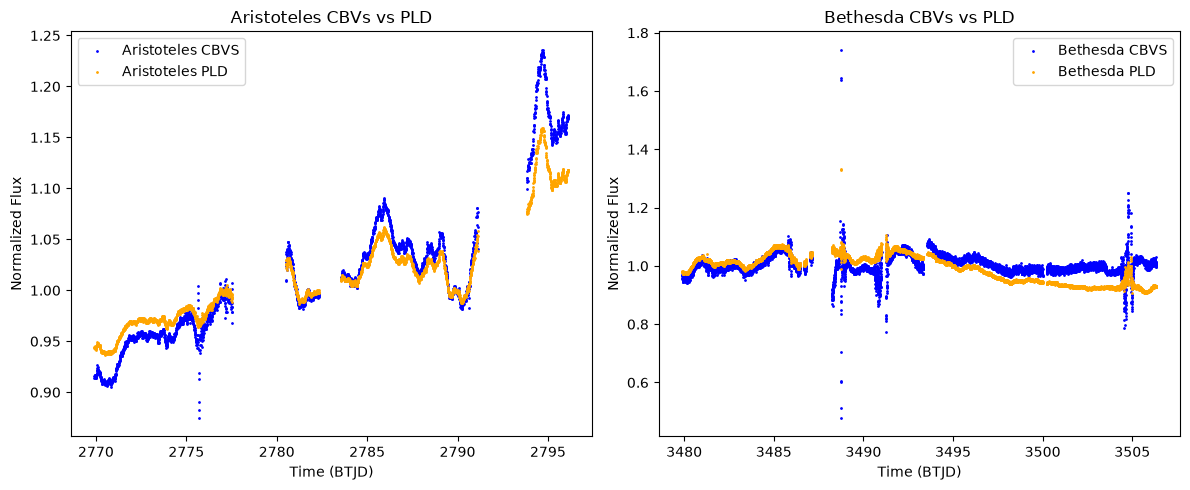

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(lc_aristoteles_cbvs.time.value, lc_aristoteles_cbvs.normalize().flux.value, color='blue', label='Aristoteles CBVS', s=1)
ax[0].scatter(lc_aristoteles_pld.time.value, lc_aristoteles_pld.normalize().flux.value, color='orange', label='Aristoteles PLD', s=1)
ax[0].set_title('Aristoteles CBVs vs PLD')
ax[0].set_xlabel('Time (BTJD)')
ax[0].set_ylabel('Normalized Flux')
ax[0].legend()

ax[1].scatter(lc_bethesda_cbvs.time.value, lc_bethesda_cbvs.normalize().flux.value, color='blue', label='Bethesda CBVS', s=1)
ax[1].scatter(lc_bethesda_pld.time.value, lc_bethesda_pld.normalize().flux.value, color='orange', label='Bethesda PLD', s=1)
ax[1].set_title('Bethesda CBVs vs PLD')
ax[1].set_xlabel('Time (BTJD)')
ax[1].set_ylabel('Normalized Flux')
ax[1].legend()

fig.tight_layout()
plt.show()

## Correctors conclusion
So to conclude correctors, to me it seems that the best approach is pld, so now we will operate over the `lc_aristoteles_pld` and `lc_bethesda_pld` light curves, which are the light curves where we applied sap -> bg removal -> pld correction

<Axes: title={'center': 'Target ID: 285.5, 2.156388, Cadence: 0'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>

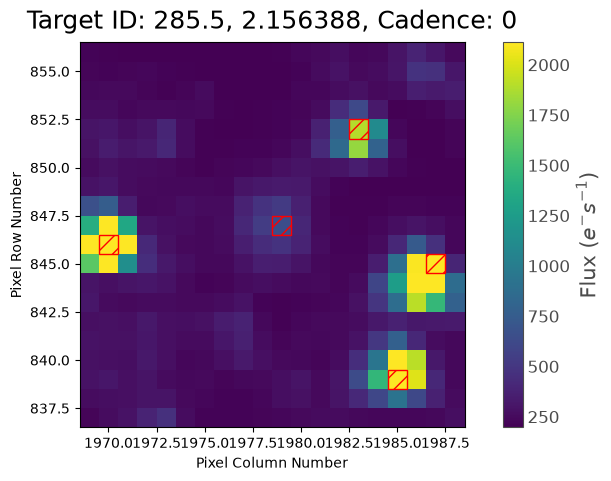

In [33]:
# for other corrections we could check trends on the entire image, for example, if the instrument has a trend to collect more 
# flux in every pixel, for that we will select some pixels and check each derivative, if the derivatives are "similar" or "equivalent"ArithmeticError

# selected pixels
pixels = [
    (9, 1),
    (10, 10),
    (8, 18),
    (2, 16),
    (15, 14)
]

pixels_mask = np.zeros(aristoteles.shape[1:], dtype=bool)
for row, col in pixels:
    pixels_mask[row, col] = True

fig, ax = plt.subplots(figsize=(10, 5))

aristoteles.plot(ax=ax, aperture_mask=pixels_mask, mask_color='red', frame=0)

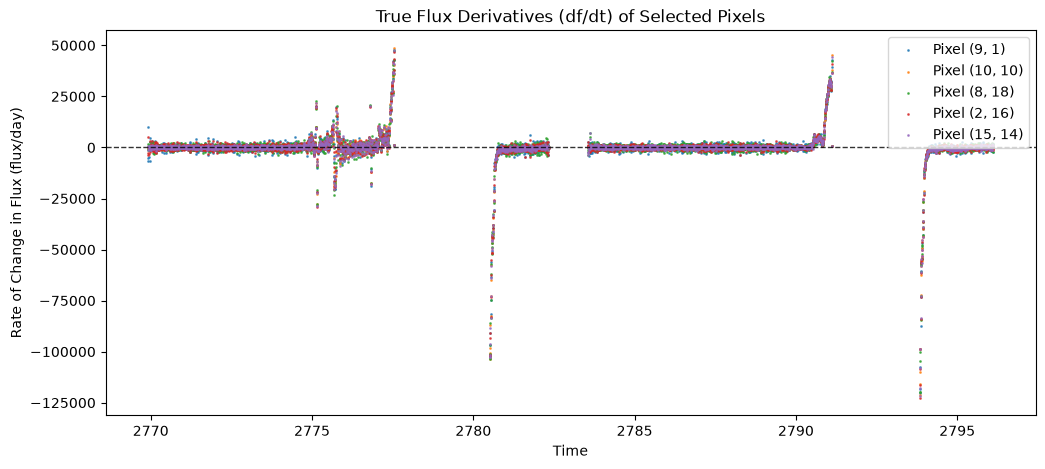

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))

time = aristoteles.time.value
time_axis = time[:-1] 

# Calculate the time step array (dt)
dt = np.diff(time)

for row, col in pixels:
    single_pixel_flux = aristoteles.flux[:, row, col]
    
    # change in flux (df)
    df = np.diff(single_pixel_flux)
    
    # temporal derivative
    true_derivative = df / dt
    
    ax.scatter(time_axis, true_derivative, label=f"Pixel ({row}, {col})", alpha=0.7, s=1)

ax.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.8)
ax.set_title("True Flux Derivatives (df/dt) of Selected Pixels")
ax.set_xlabel("Time")
ax.set_ylabel("Rate of Change in Flux (flux/day)")
ax.legend(loc='upper right')

plt.show()

# Analysis
Since now we have more or less clean light curves, we can start by analyzing them, one method is FFT

In [35]:
def fft_lightcurve(flux: np.ndarray, time: np.ndarray, center: bool = False, min_period: float = 0.0, max_period: float = np.inf) -> tuple[np.ndarray, np.ndarray]:
    """
    Compute the FFT of a light curve and return the frequencies and magnitudes.
    """
    if center:
        flux = flux - np.nanmean(flux)
        
    fft_lc = np.fft.fft(flux)
    
    dt = np.median(np.diff(time))
    frequencies = np.fft.fftfreq(len(fft_lc), d=dt)
    
    magnitudes = np.abs(fft_lc) / len(fft_lc)

    n_samples = len(fft_lc) // 2
    frequencies = frequencies[:n_samples]
    magnitudes = magnitudes[:n_samples]

    # trim for periods
    if min_period > 0.0:
        max_freq = 1.0 / min_period
        frequencies = frequencies[frequencies <= max_freq]
        magnitudes = magnitudes[:len(frequencies)]

    if max_period < np.inf:
        min_freq = 1.0 / max_period
        frequencies = frequencies[frequencies >= min_freq]
        magnitudes = magnitudes[:len(frequencies)]

    return frequencies, magnitudes

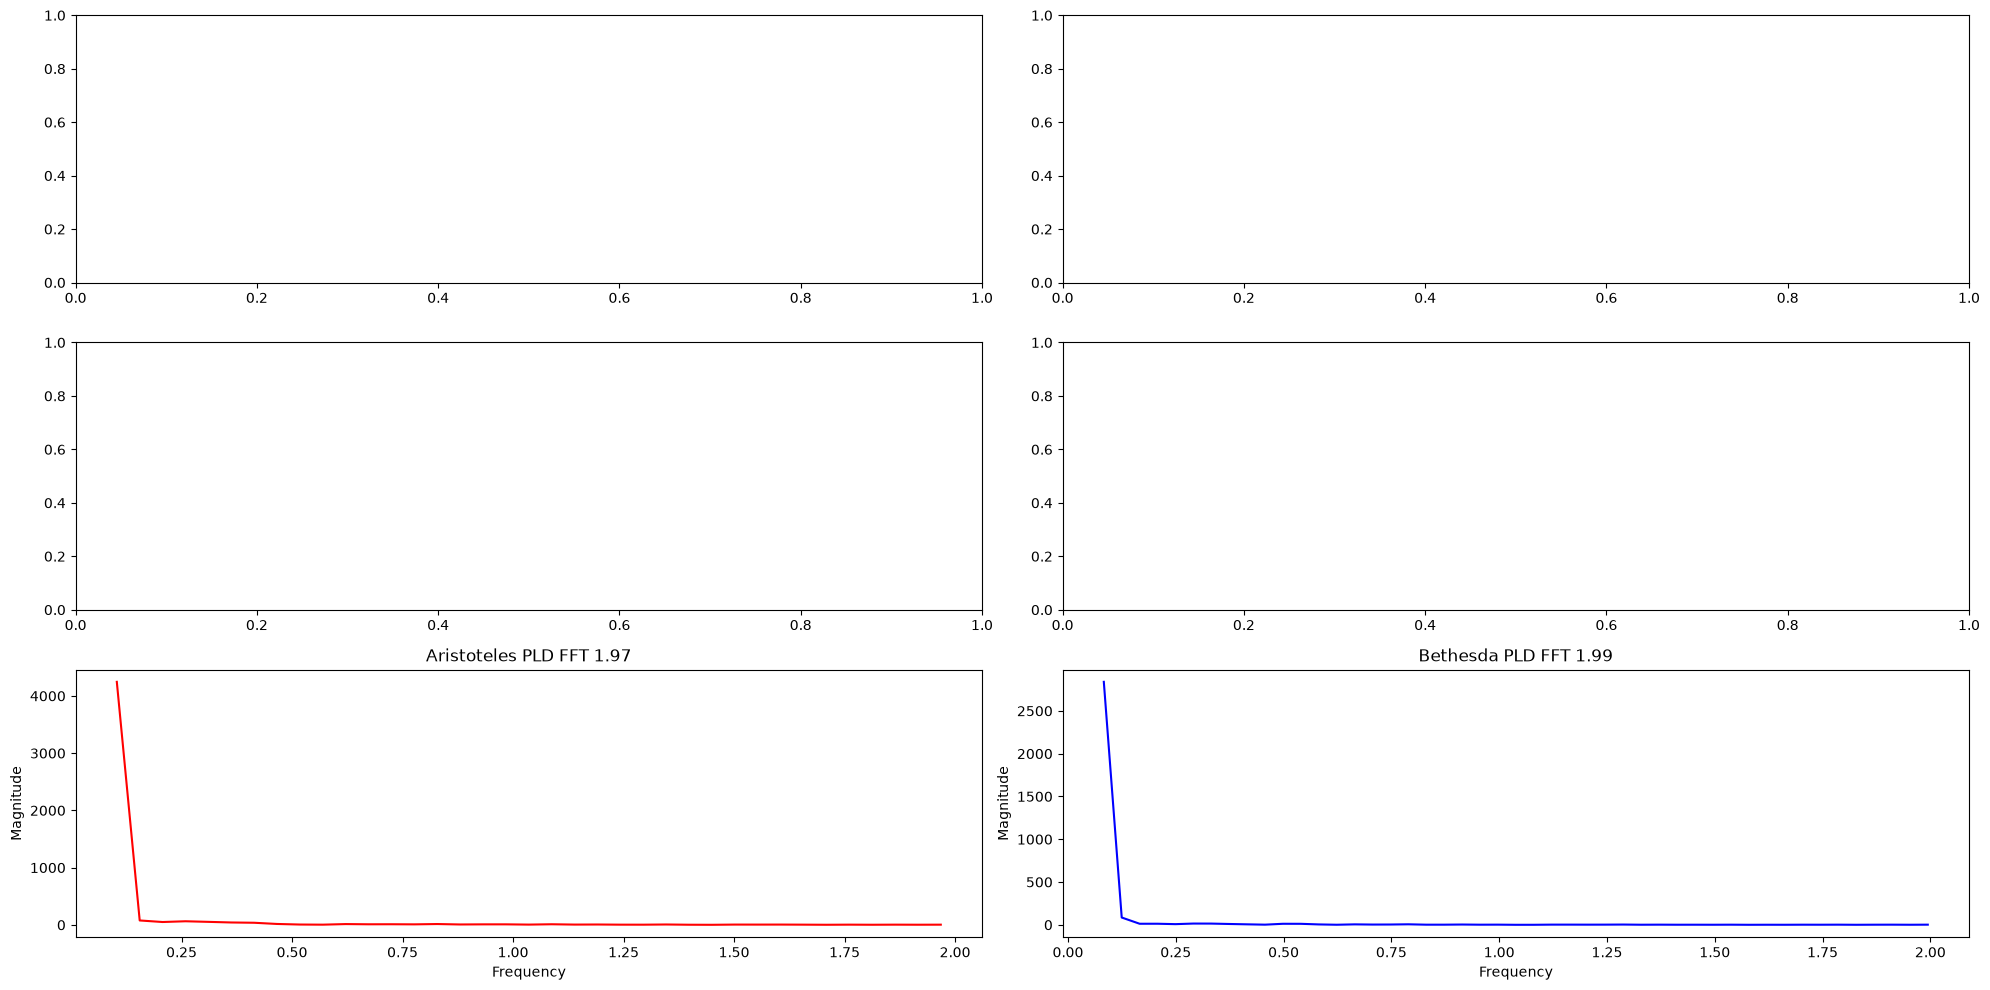

In [36]:
def plot_fft(frequencies: np.ndarray, magnitudes: np.ndarray, title: str, color: str, ax: plt.Axes) -> None:
    ax.plot(frequencies, magnitudes, color=color)
    ax.set_title(f"{title} {np.max(frequencies):.2f}")
    ax.set_xlabel('Frequency')
    ax.set_ylabel('Magnitude')
    # ax.set_xscale('log')
    # ax.set_yscale('log')

fig, ax = plt.subplots(3, 2, figsize=(20, 10))

aristoteles_default_freqs, aristoteles_default_mags = fft_lightcurve(lc_aristoteles_default.flux.value, lc_aristoteles_default.time.value)
aristoteles_cbvs_freqs, aristoteles_cbvs_mags = fft_lightcurve(lc_aristoteles_cbvs.flux.value, lc_aristoteles_cbvs.time.value)
aristoteles_pld_freqs, aristoteles_pld_mags = fft_lightcurve(lc_aristoteles_pld.flux.value, lc_aristoteles_pld.time.value, min_period=0.5, max_period=14.0)

bethesda_default_freqs, bethesda_default_mags = fft_lightcurve(lc_bethesda_default.flux.value, lc_bethesda_default.time.value)
bethesda_cbvs_freqs, bethesda_cbvs_mags = fft_lightcurve(lc_bethesda_cbvs.flux.value, lc_bethesda_cbvs.time.value)
bethesda_pld_freqs, bethesda_pld_mags = fft_lightcurve(lc_bethesda_pld.flux.value, lc_bethesda_pld.time.value, min_period=0.5, max_period=14.0)

n_samples_ari = len(aristoteles_default_freqs)
n_samples_bet = len(bethesda_default_freqs)

# plot_fft(aristoteles_default_freqs[:n_samples_ari], aristoteles_default_mags[:n_samples_ari], 'Aristoteles Default FFT', 'blue', ax[0, 0])
# plot_fft(bethesda_default_freqs[:n_samples_bet], bethesda_default_mags[:n_samples_bet], 'Bethesda Default FFT', 'blue', ax[0, 1])
# plot_fft(aristoteles_cbvs_freqs[:n_samples_ari], aristoteles_cbvs_mags[:n_samples_ari], 'Aristoteles CBVS FFT', 'green', ax[1, 0])
# plot_fft(bethesda_cbvs_freqs[:n_samples_bet], bethesda_cbvs_mags[:n_samples_bet], 'Bethesda CBVS FFT', 'green', ax[1, 1])
plot_fft(aristoteles_pld_freqs[:n_samples_ari], aristoteles_pld_mags[:n_samples_ari], 'Aristoteles PLD FFT', 'red', ax[2, 0])
plot_fft(bethesda_pld_freqs[:n_samples_bet], bethesda_pld_mags[:n_samples_bet], 'Bethesda PLD FFT', 'blue', ax[2, 1])

plt.tight_layout()
plt.show()

In [37]:
# most significant frequencies for each light curve
for lc, name in zip([lc_aristoteles_default, lc_aristoteles_cbvs, lc_aristoteles_pld, lc_bethesda_default, lc_bethesda_cbvs, lc_bethesda_pld],
                ['Aristoteles Default', 'Aristoteles CBVS', 'Aristoteles PLD', 'Bethesda Default', 'Bethesda CBVS', 'Bethesda PLD']):
    freqs, mags = fft_lightcurve(lc.flux.value, lc.time.value)
    significant_indices = np.argsort(mags)[-5:]  # Get indices of the 5 most significant frequencies
    significant_freqs = freqs[significant_indices]
    significant_mags = mags[significant_indices]
    
    print(f"Most significant frequencies for {name}:")
    for freq, mag in zip(significant_freqs, significant_mags):
        print(f"Frequency: {freq:.8f}, Magnitude: {mag:.6f}")
    print()

Most significant frequencies for Aristoteles Default:
Frequency: 0.41424526, Magnitude: 1131.409058
Frequency: 0.31068394, Magnitude: 1176.546997
Frequency: 0.20712263, Magnitude: 1650.174438
Frequency: 0.10356131, Magnitude: 2293.073242
Frequency: 0.00000000, Magnitude: 6561.453613

Most significant frequencies for Aristoteles CBVS:
Frequency: 0.10356131, Magnitude: 2.335409
Frequency: 0.20712263, Magnitude: 2.497197
Frequency: 0.15534197, Magnitude: 2.931092
Frequency: 0.05178066, Magnitude: 3.668685
Frequency: 0.00000000, Magnitude: 136.455230

Most significant frequencies for Aristoteles PLD:
Frequency: 0.10356131, Magnitude: 50.165737
Frequency: 0.20712263, Magnitude: 52.846250
Frequency: 0.15534197, Magnitude: 63.216204
Frequency: 0.05178066, Magnitude: 77.249654
Frequency: 0.00000000, Magnitude: 4246.013892

Most significant frequencies for Bethesda Default:
Frequency: 0.24925180, Magnitude: 2768.820557
Frequency: 0.37387769, Magnitude: 3421.675049
Frequency: 0.45696162, Magnitu

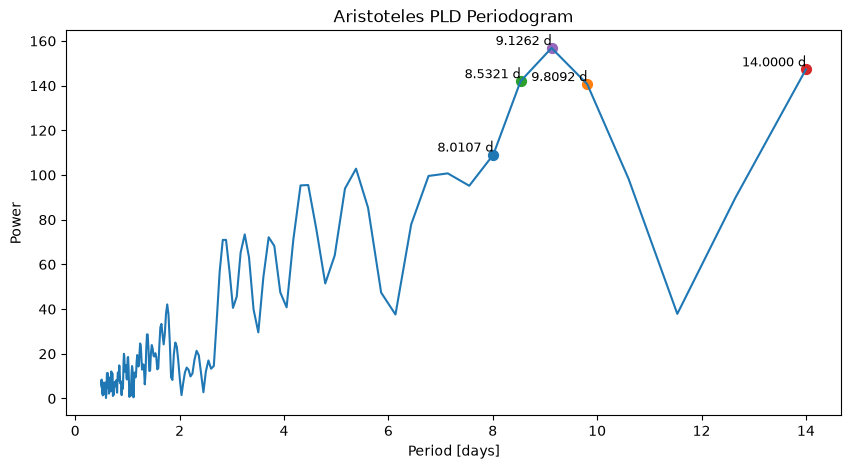

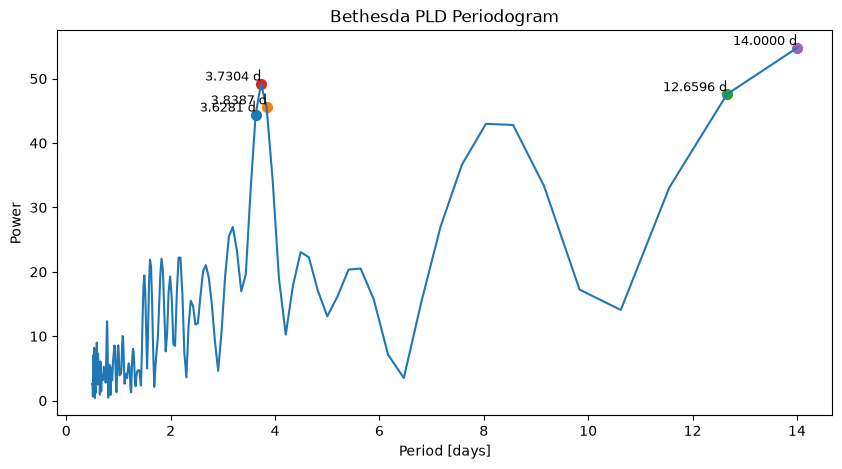

In [38]:
aristoteles_periodogram = lc_aristoteles_pld.to_periodogram(method="ls", minimum_period=0.5, maximum_period=14)
bethesda_periodogram = lc_bethesda_pld.to_periodogram(method="ls", minimum_period=0.5, maximum_period=14)

# 5 most significant periods for each light curve and then plot
def plot_significant_periods(periodogram, name):

    significant_indices = np.argsort(
        periodogram.power.value
    )[-5:]

    significant_periods = periodogram.period[significant_indices]
    significant_powers = periodogram.power[significant_indices]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        periodogram.period.to_value("day"),
        periodogram.power.value
    )

    ax.set_title(f"{name} Periodogram")
    ax.set_xlabel("Period [days]")
    ax.set_ylabel("Power")

    for period, power in zip(
        significant_periods,
        significant_powers
    ):

        period_days = period.to_value("day")
        power_value = power.value

        ax.scatter(
            period_days,
            power_value,
            s=50
        )

        ax.text(
            period_days,
            power_value,
            f"{period_days:.4f} d",
            fontsize=9,
            ha="right",
            va="bottom"
        )

    plt.show()
    


plot_significant_periods(aristoteles_periodogram, "Aristoteles PLD")
plot_significant_periods(bethesda_periodogram, "Bethesda PLD")


<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

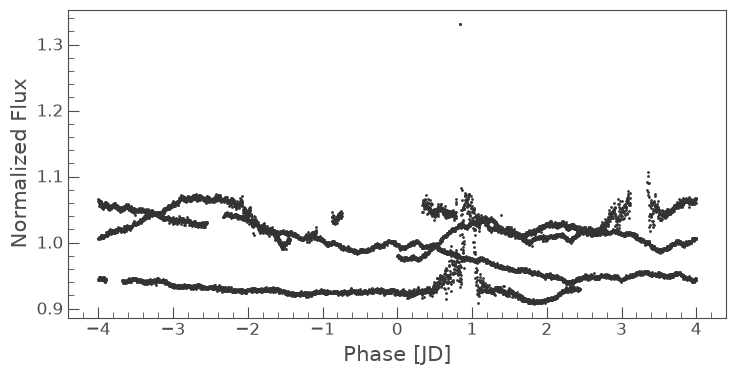

In [39]:
lc_bethesda_pld.normalize().fold(period=8).scatter()

In this section i will apply Phase Dispersion Minimization (PDM) (method found from the HMM article, Stellingwerf's method 1978 then it was improved by other researchers aka PDM2 method) to the light curves, this method is useful for finding periodic signals in unevenly spaced data (non-parametric method)

To understand this method, we can think of it as a method that tries to fold the light curve over a range of periods and then measure how well the data points align with each other, if the data points align well, it means that the period is likely to be correct, if they do not align well, it means that the period is likely to be incorrect.

In [52]:
from PyAstronomy.pyTiming import pyPDM


def process_pdm(
    time: np.ndarray,
    flux: np.ndarray,
    min_period=None,
    max_period=None,
    n_bins=10,
    samples_per_period=10,
    oversampling=10,
    covers=3,
    n_candidates=5,
    candidate_separation=0.05,
    title="Sh 2-71"
):

    good = np.isfinite(time) & np.isfinite(flux)

    time = time[good]
    flux = flux[good]

    if len(time) < 3:
        raise ValueError("Not enough valid observations for PDM.")

    # Sort chronologically
    order_time = np.argsort(time)

    time = time[order_time]
    flux = flux[order_time]

    baseline = time.max() - time.min()

    dt = np.diff(time)

    sampling_duration = np.median(dt)

    print(f"Observational baseline: {baseline:.6f} days")
    print(f"Number of observations: {len(time)}")

    print(
        f"Typical sampling duration: "
        f"{sampling_duration:.8f} days "
        f"({sampling_duration * 86400:.2f} s)"
    )
    if min_period is None:
        min_period = samples_per_period * sampling_duration

    if max_period is None:
        max_period = baseline / 2


    if min_period <= 0:
        raise ValueError("min_period must be greater than zero.")

    if max_period <= min_period:
        raise ValueError(
            "max_period must be larger than min_period."
        )


    print(f"Minimum searched period: {min_period:.6f} days")
    print(f"Maximum searched period: {max_period:.6f} days")

    min_frequency = 1.0 / max_period
    max_frequency = 1.0 / min_period


    # Natural frequency resolution is approximately 1 / baseline.
    df = 1.0 / (oversampling * baseline)


    print(f"Frequency resolution: {df:.8f} 1/day")

    scanner = pyPDM.Scanner(
        minVal=min_frequency,
        maxVal=max_frequency,
        dVal=df,
        mode="frequency"
    )

    pdm = pyPDM.PyPDM(time, flux)

    frequency, theta = pdm.pdmEquiBinCover(
        n_bins,
        covers,
        scanner
    )


    frequency = np.asarray(frequency)
    theta = np.asarray(theta)

    valid = (
        np.isfinite(frequency)
        & np.isfinite(theta)
        & (frequency > 0)
    )

    frequency = frequency[valid]
    theta = theta[valid]
    
    period = 1.0 / frequency


    # Frequency increases while period decreases,
    # so sort everything by increasing period.
    order = np.argsort(period)

    period = period[order]
    theta = theta[order]

    # global minimum

    idx = np.nanargmin(theta)

    best_period = period[idx]
    best_theta = theta[idx]

    cycles_observed = baseline / best_period


    print("\nBest PDM candidate:")
    print(f"Period: {best_period:.6f} days")
    print(f"Theta: {best_theta:.6f}")
    print(f"Cycles observed: {cycles_observed:.2f}")

    # local minima

    local_minima = np.where(
        (theta[1:-1] < theta[:-2])
        & (theta[1:-1] < theta[2:])
    )[0] + 1

    if idx not in local_minima:
        local_minima = np.append(local_minima, idx)


    # Sort minima by Theta: smallest first
    local_minima = local_minima[
        np.argsort(theta[local_minima])
    ]


    selected = []

    for i in local_minima:

        p = period[i]

        # Do not count several samples from the same broad trough
        # as separate candidate periods
        independent = True

        for j in selected:

            p_previous = period[j]

            relative_difference = (
                abs(p - p_previous)
                / p_previous
            )

            if relative_difference < candidate_separation:
                independent = False
                break


        if independent:
            selected.append(i)


        if len(selected) >= n_candidates:
            break


    print("\nStrongest independent PDM minima:")

    for rank, i in enumerate(selected, start=1):

        candidate_cycles = baseline / period[i]

        print(
            f"{rank}: "
            f"P = {period[i]:.6f} d, "
            f"Theta = {theta[i]:.6f}, "
            f"cycles = {candidate_cycles:.2f}"
        )


    # phase and cycle

    phase = (
        (time - time.min())
        / best_period
    ) % 1


    cycle_number = np.floor(
        (time - time.min())
        / best_period
    ).astype(int)

    fig, ax = plt.subplots(
        3,
        1,
        figsize=(11, 13)
    )


    ax[0].scatter(
        time,
        flux,
        s=4,
        alpha=0.7
    )

    ax[0].set_xlabel("Time [days]")
    ax[0].set_ylabel("Flux")
    ax[0].set_title(f"{title} - Original light curve")

    ax[0].grid(alpha=0.3)

    ax[1].plot(
        period,
        theta
    )


    for rank, i in enumerate(selected, start=1):

        ax[1].axvline(
            period[i],
            linestyle="--",
            alpha=0.6
        )

        ax[1].text(
            period[i],
            theta[i],
            f" {rank}",
            fontsize=9
        )


    ax[1].axvline(
        best_period,
        linestyle="--",
        linewidth=2,
        label=f"Best P = {best_period:.4f} d"
    )

    ax[1].set_xlabel("Period [days]")
    ax[1].set_ylabel("PDM Theta")
    ax[1].set_title(f"PDM period search - {title}")

    ax[1].legend()
    ax[1].grid(alpha=0.3)

    scatter = ax[2].scatter(
        phase,
        flux,
        c=cycle_number,
        s=5,
        alpha=0.7
    )


    fig.colorbar(
        scatter,
        ax=ax[2],
        label="Cycle number"
    )


    ax[2].set_xlabel("Phase")
    ax[2].set_ylabel("Flux")

    ax[2].set_title(
        f"{title} - Folded at P = {best_period:.4f} d"
    )

    ax[2].grid(alpha=0.3)


    plt.tight_layout()
    plt.show()

    return {
        "best_period": best_period,
        "best_theta": best_theta,
        "cycles_observed": cycles_observed,

        "period": period,
        "theta": theta,

        "candidate_periods": period[selected],
        "candidate_theta": theta[selected],

        "baseline": baseline,
        "sampling_duration": sampling_duration,

        "min_period": min_period,
        "max_period": max_period
    }

Observational baseline: 26.214984 days
Number of observations: 2781
Typical sampling duration: 0.00694435 days (599.99 s)
Minimum searched period: 0.069443 days
Maximum searched period: 13.107492 days
Frequency resolution: 0.00381461 1/day

Best PDM candidate:
Period: 8.738328 days
Theta: 0.585616
Cycles observed: 3.00

Strongest independent PDM minima:
1: P = 8.738328 d, Theta = 0.585616, cycles = 3.00
2: P = 7.281940 d, Theta = 0.848296, cycles = 3.60
3: P = 5.461455 d, Theta = 0.856451, cycles = 4.80
4: P = 4.369164 d, Theta = 0.868604, cycles = 6.00
5: P = 3.276873 d, Theta = 0.923016, cycles = 8.00
6: P = 3.744998 d, Theta = 0.929781, cycles = 7.00
7: P = 2.849455 d, Theta = 0.935109, cycles = 9.20
8: P = 0.097237 d, Theta = 0.965045, cycles = 269.60
9: P = 0.104152 d, Theta = 0.971349, cycles = 251.70
10: P = 0.111128 d, Theta = 0.973105, cycles = 235.90


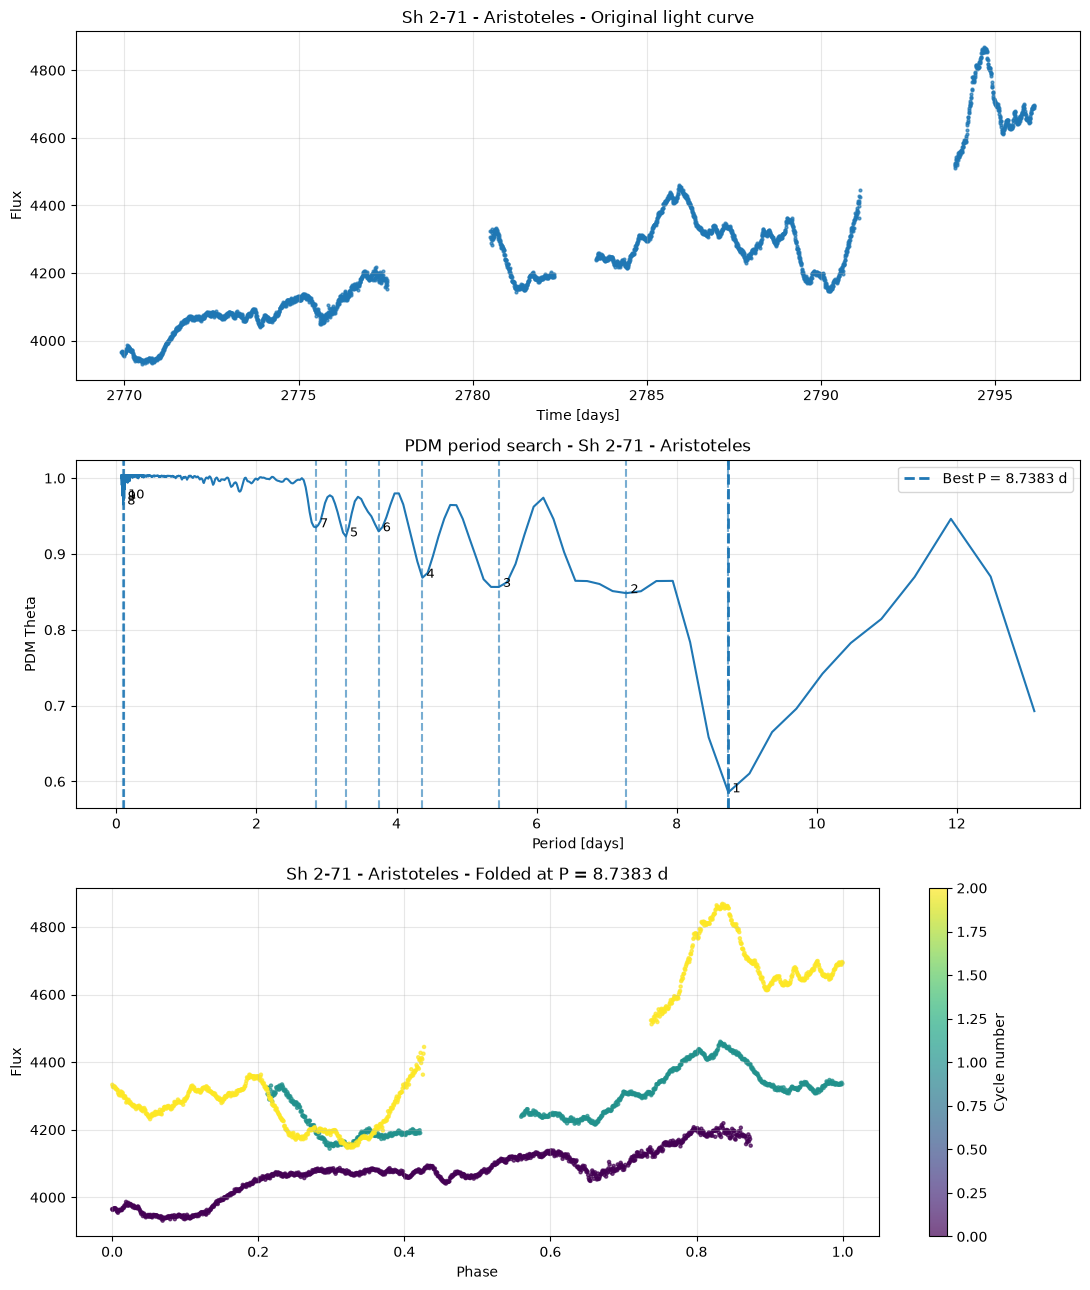

Observational baseline: 26.444691 days
Number of observations: 10399
Typical sampling duration: 0.00231484 days (200.00 s)
Minimum searched period: 0.023148 days
Maximum searched period: 13.222346 days
Frequency resolution: 0.00378148 1/day

Best PDM candidate:
Period: 7.555626 days
Theta: 0.887292
Cycles observed: 3.50

Strongest independent PDM minima:
1: P = 7.555626 d, Theta = 0.887292, cycles = 3.50
2: P = 11.018621 d, Theta = 0.904048, cycles = 2.40
3: P = 3.724604 d, Theta = 0.924125, cycles = 7.10
4: P = 8.814897 d, Theta = 0.931616, cycles = 3.00
5: P = 6.449925 d, Theta = 0.964832, cycles = 4.10
6: P = 0.030095 d, Theta = 0.966543, cycles = 878.70
7: P = 5.396876 d, Theta = 0.968279, cycles = 4.90
8: P = 3.224962 d, Theta = 0.969646, cycles = 8.20
9: P = 4.407449 d, Theta = 0.972182, cycles = 6.00
10: P = 6.010157 d, Theta = 0.976234, cycles = 4.40


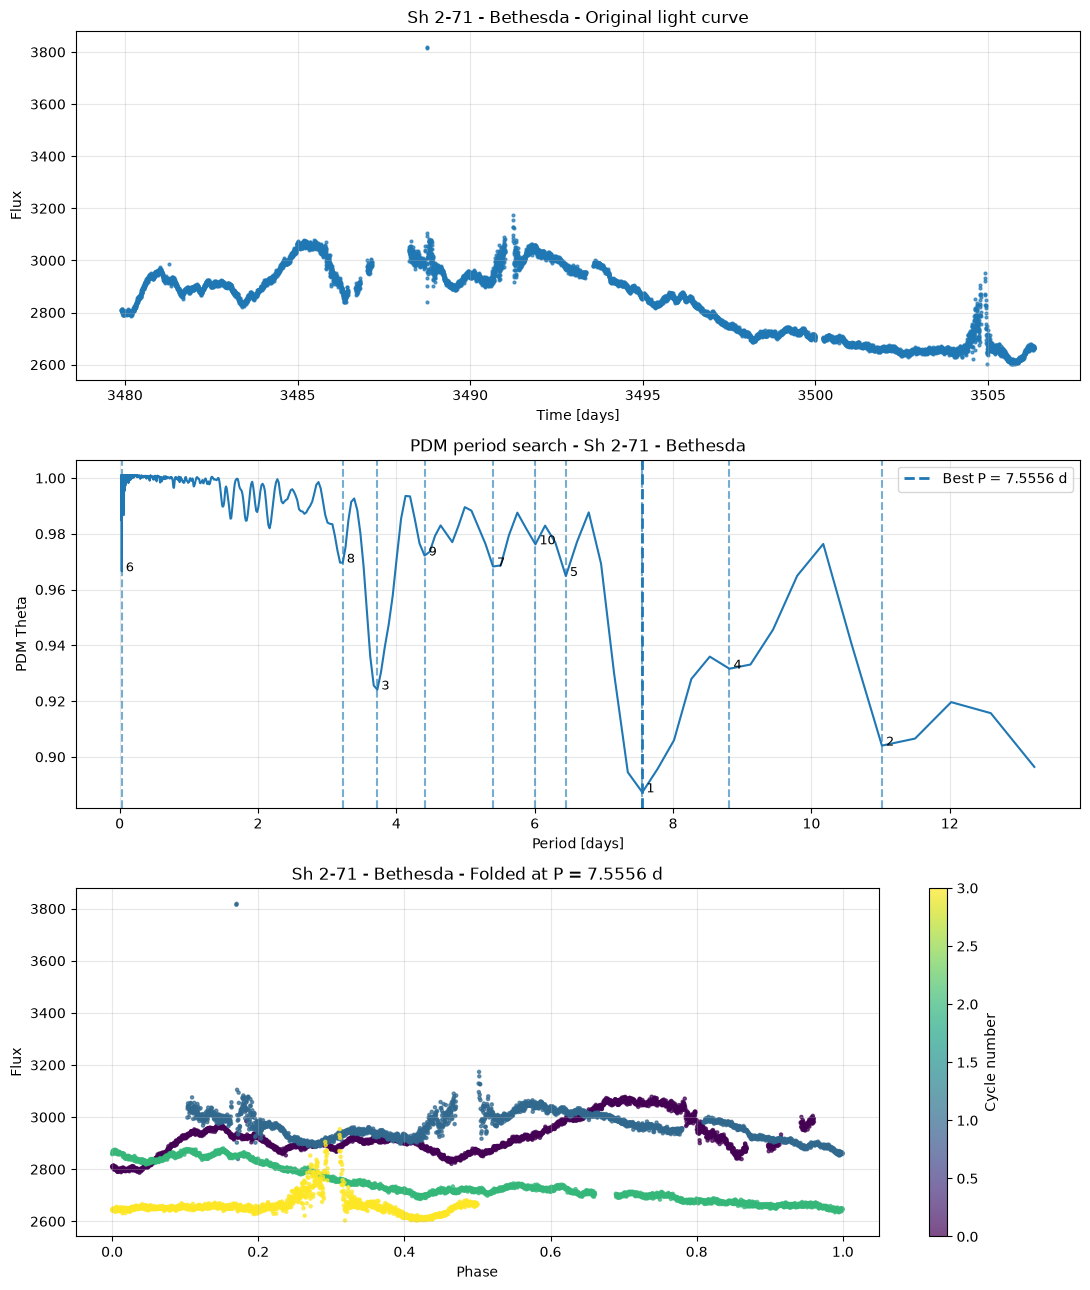

In [53]:
# The minimum period is constrained by the sampling cadence.
# The formal Nyquist limit would be:
#
#     P_min = 2 * cadence
#
# However, PDM benefits from having several samples per cycle.
# We therefore impose a more conservative minimum period.
#
# The maximum period is constrained by the observational baseline.
# We use:
#
#     P_max = baseline / 2
#
# so that every searched period contains at least approximately
# two cycles within the observations.

a_pdm = process_pdm(
    lc_aristoteles_pld.time.value,
    lc_aristoteles_pld.flux.value,
    n_bins=10,
    n_candidates=10,
    title="Sh 2-71 - Aristoteles"
)

b_pdm = process_pdm(
    lc_bethesda_pld.time.value,
    lc_bethesda_pld.flux.value,
    n_bins=10,
    n_candidates=10,
    title="Sh 2-71 - Bethesda"
)

In [42]:
from PyAstronomy import pyTiming as pyt
import numpy as np
import matplotlib.pyplot as plt


def process_stringlength(
    lc,
    min_period=None,
    max_period=None,
    samples_per_period=10,
    oversampling=10,
    title="Sh 2-71"
):

    time = np.asarray(lc.time.value)
    flux = np.asarray(lc.flux.value)

    good = np.isfinite(time) & np.isfinite(flux)

    time = time[good]
    flux = flux[good]

    order = np.argsort(time)

    time = time[order]
    flux = flux[order]


    # observational parameters
    baseline = time.max() - time.min()

    sampling_duration = np.median(
        np.diff(time)
    )


    # search limits
    if min_period is None:
        min_period = (
            samples_per_period
            * sampling_duration
        )

    if max_period is None:
        max_period = baseline / 2


    # frequency range
    min_frequency = 1.0 / max_period
    max_frequency = 1.0 / min_period

    df = 1.0 / (
        oversampling * baseline
    )


    frequencies = np.arange(
        min_frequency,
        max_frequency,
        df
    )


    trial_periods = 1.0 / frequencies

    trial_periods = np.sort(
        trial_periods
    )


    # string length
    periods, string_length = (
        pyt.stringlength_dat(
            time,
            flux,
            tps=trial_periods,
            closed=True
        )
    )


    periods = np.asarray(periods)
    string_length = np.asarray(string_length)


    # best candidate
    idx = np.nanargmin(
        string_length
    )

    best_period = periods[idx]
    best_length = string_length[idx]

    cycles_observed = (
        baseline / best_period
    )


    print(
        f"Baseline: {baseline:.6f} days"
    )

    print(
        f"Minimum period: {min_period:.6f} days"
    )

    print(
        f"Maximum period: {max_period:.6f} days"
    )

    print()
    print(
        f"Best candidate: {best_period:.6f} days"
    )

    print(
        f"String length: {best_length:.6f}"
    )

    print(
        f"Cycles observed: {cycles_observed:.2f}"
    )


    # boundary diagnostic
    width = (
        max_period - min_period
    )

    if (
        best_period - min_period
        < 0.02 * width
    ):
        print(
            "WARNING: Best candidate is close "
            "to lower search boundary."
        )

    if (
        max_period - best_period
        < 0.02 * width
    ):
        print(
            "WARNING: Best candidate is close "
            "to upper search boundary."
        )


    # plot
    fig, ax = plt.subplots(
        figsize=(10, 5)
    )

    ax.plot(
        periods,
        string_length
    )

    ax.axvline(
        best_period,
        linestyle="--",
        label=f"P = {best_period:.4f} d"
    )

    ax.set_xlabel("Period [days]")
    ax.set_ylabel("String Length")
    ax.set_title(
        f"String Length - {title}"
    )

    ax.legend()
    ax.grid(alpha=0.3)

    plt.show()


    return {
        "period": periods,
        "string_length": string_length,
        "best_period": best_period,
        "best_length": best_length,
        "baseline": baseline,
        "sampling_duration": sampling_duration,
        "min_period": min_period,
        "max_period": max_period
    }

Baseline: 26.214984 days
Minimum period: 0.069443 days
Maximum period: 13.107492 days

Best candidate: 0.069462 days
String length: 24.566583
Cycles observed: 377.40


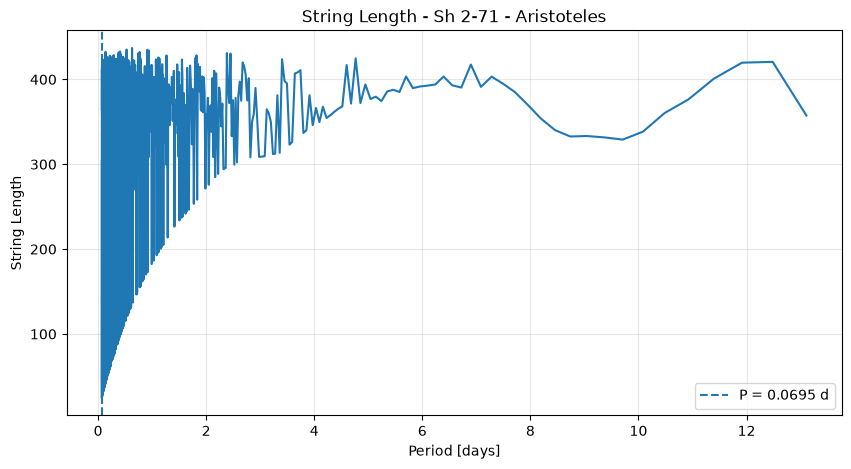

In [43]:
a_string = process_stringlength(
    lc_aristoteles_pld,
    title="Sh 2-71 - Aristoteles"
)

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

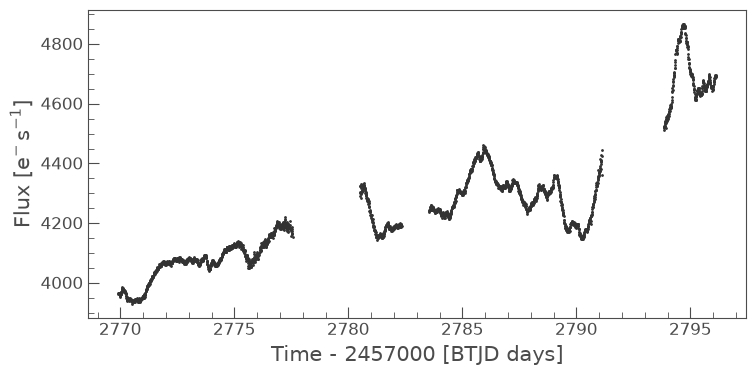

In [44]:
lc_aristoteles_pld.scatter()



# Trends normalization
In this section i will aproximate long trends to the pld light curves and then remove them to again pass through the period analysis

In [57]:
def identify_linear_trend(lc):
    # least squares linear fit
    time = lc.time.value
    flux = lc.flux.value

    # based on the linear equation Ax = B
    X_bias = np.vstack([time, np.ones(len(time))]).T

    # Solve for the coefficients (slope and intercept)
    slope, intercept = np.linalg.lstsq(X_bias, flux, rcond=None)[0]

    # Calculate the fitted values
    fitted_values = slope * time + intercept

    # Calculate the residuals
    residuals = flux - fitted_values

    return {"slope": slope, "intercept": intercept, "fitted_values": fitted_values, "residuals": residuals}

In [60]:
def identify_cuadratic_trend(lc):
    # least squares quadratic fit
    time = lc.time.value
    flux = lc.flux.value

    # based on the quadratic equation Ax^2 + Bx + C = y
    X_bias = np.vstack([time**2, time, np.ones(len(time))]).T

    # Solve for the coefficients (A, B, C)
    coeffs = np.linalg.lstsq(X_bias, flux, rcond=None)[0]

    # Calculate the fitted values
    fitted_values = coeffs[0] * time**2 + coeffs[1] * time + coeffs[2]

    # Calculate the residuals
    residuals = flux - fitted_values

    return {"coefficients": coeffs, "fitted_values": fitted_values, "residuals": residuals}

In [63]:
def identify_cubic_trend(lc):
    # least squares cubic fit
    time = lc.time.value
    flux = lc.flux.value

    # based on the cubic equation Ax^3 + Bx^2 + Cx + D = y
    X_bias = np.vstack([time**3, time**2, time, np.ones(len(time))]).T

    # Solve for the coefficients (A, B, C, D)
    coeffs = np.linalg.lstsq(X_bias, flux, rcond=None)[0]

    # Calculate the fitted values
    fitted_values = coeffs[0] * time**3 + coeffs[1] * time**2 + coeffs[2] * time + coeffs[3]

    # Calculate the residuals
    residuals = flux - fitted_values

    return {"coefficients": coeffs, "fitted_values": fitted_values, "residuals": residuals}

In [65]:
def identify_polynomial_trend(lc, degree=1):
    # least squares polynomial fit of specified degree
    time = lc.time.value
    flux = lc.flux.value

    # Create the Vandermonde matrix for polynomial fitting
    X_bias = np.vander(time, N=degree + 1, increasing=True)

    # Solve for the coefficients
    coeffs = np.linalg.lstsq(X_bias, flux, rcond=None)[0]

    # Calculate the fitted values
    fitted_values = np.polyval(coeffs[::-1], time)

    # Calculate the residuals
    residuals = flux - fitted_values

    return {"coefficients": coeffs, "fitted_values": fitted_values, "residuals": residuals}

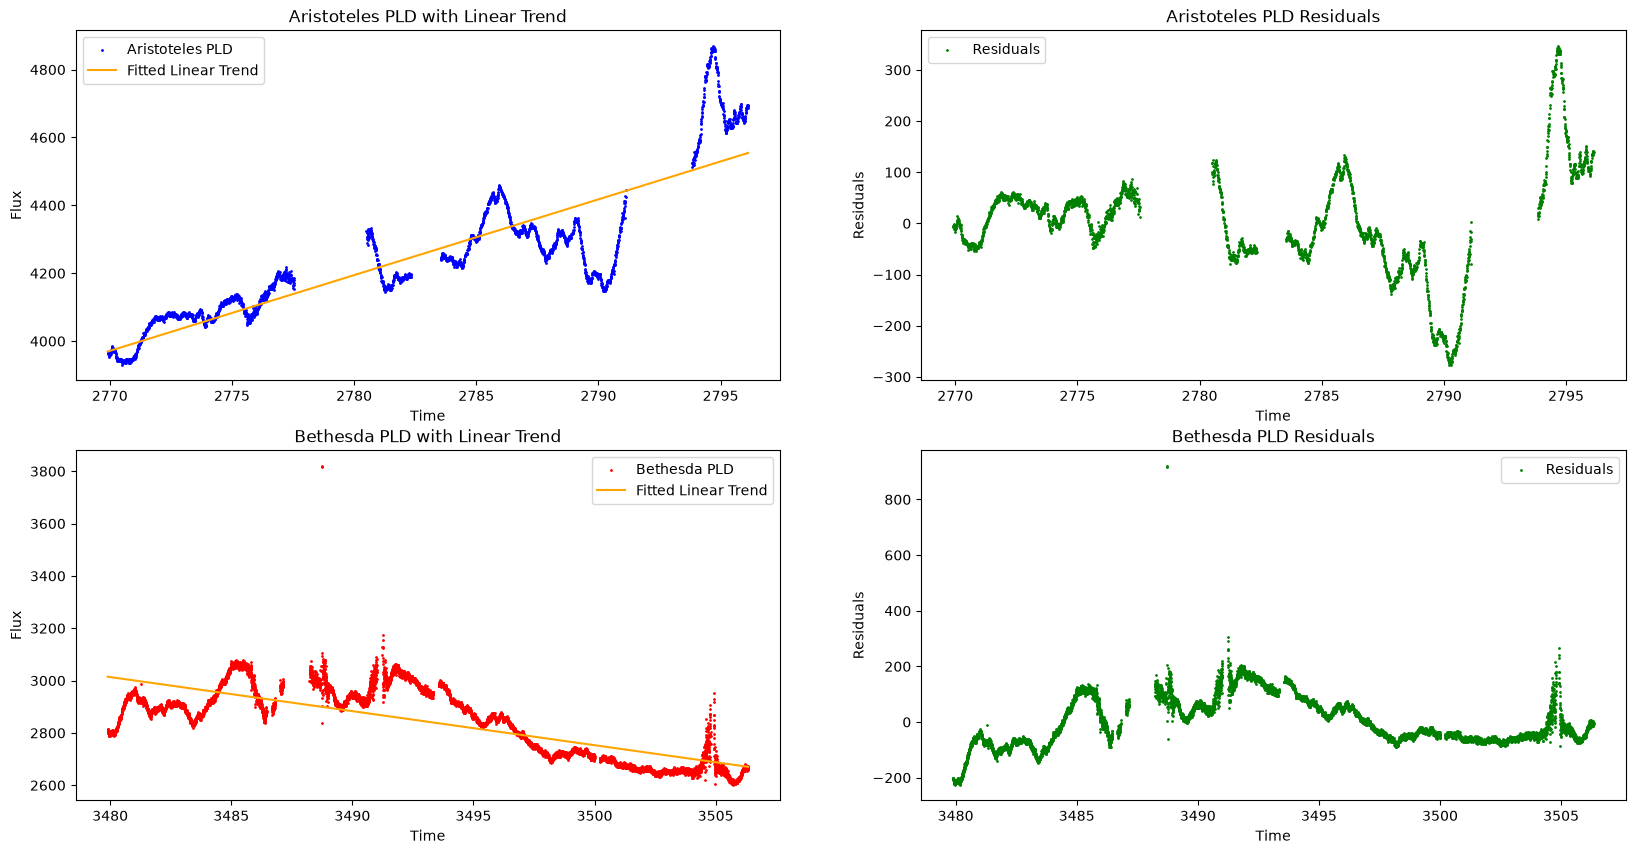

In [58]:
aristoteles_linear_trend = identify_linear_trend(lc_aristoteles_pld)
bethesda_linear_trend = identify_linear_trend(lc_bethesda_pld)

fig, ax = plt.subplots(2, 2, figsize=(20, 10))

ax[0, 0].scatter(lc_aristoteles_pld.time.value, lc_aristoteles_pld.flux.value, color='blue', s=1, label='Aristoteles PLD')
ax[0, 0].plot(lc_aristoteles_pld.time.value, aristoteles_linear_trend["fitted_values"], color='orange', label='Fitted Linear Trend')
ax[0, 0].set_title('Aristoteles PLD with Linear Trend')
ax[0, 0].set_xlabel('Time')
ax[0, 0].set_ylabel('Flux')
ax[0, 0].legend()

ax[0, 1].scatter(lc_aristoteles_pld.time.value, aristoteles_linear_trend["residuals"], color='green', s=1, label='Residuals')
ax[0, 1].set_title('Aristoteles PLD Residuals')
ax[0, 1].set_xlabel('Time')
ax[0, 1].set_ylabel('Residuals')
ax[0, 1].legend()

ax[1, 0].scatter(lc_bethesda_pld.time.value, lc_bethesda_pld.flux.value, color='red', s=1, label='Bethesda PLD')
ax[1, 0].plot(lc_bethesda_pld.time.value, bethesda_linear_trend["fitted_values"], color='orange', label='Fitted Linear Trend')
ax[1, 0].set_title('Bethesda PLD with Linear Trend')
ax[1, 0].set_xlabel('Time')
ax[1, 0].set_ylabel('Flux')
ax[1, 0].legend()

ax[1, 1].scatter(lc_bethesda_pld.time.value, bethesda_linear_trend["residuals"], color='green', s=1, label='Residuals')
ax[1, 1].set_title('Bethesda PLD Residuals')
ax[1, 1].set_xlabel('Time')
ax[1, 1].set_ylabel('Residuals')
ax[1, 1].legend()


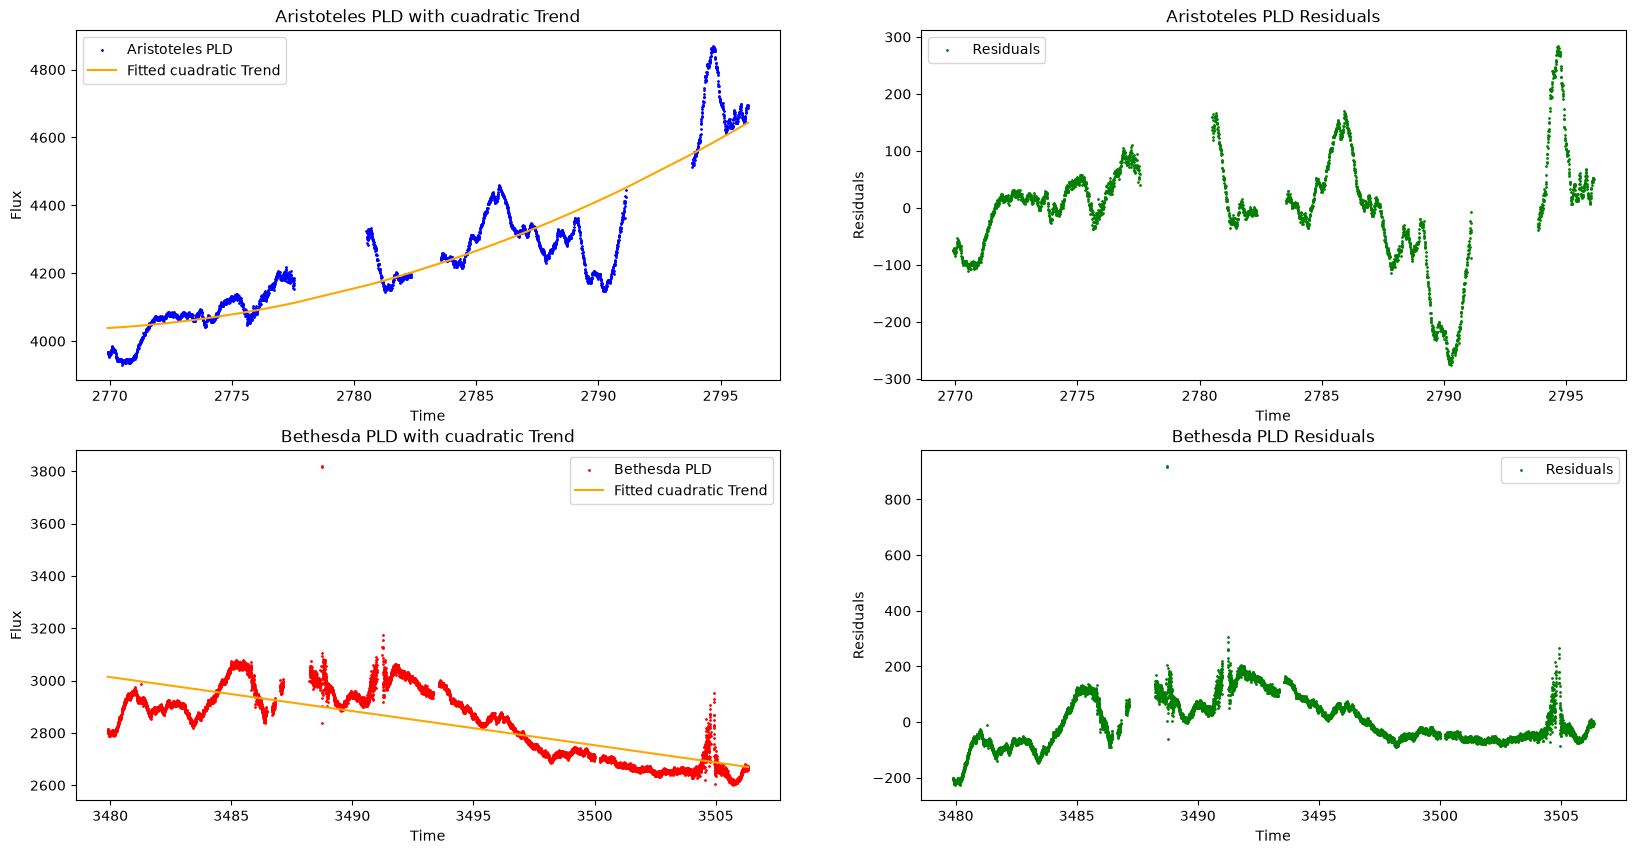

In [61]:
aristoteles_cuadratic_trend = identify_cuadratic_trend(lc_aristoteles_pld)
bethesda_cuadratic_trend = identify_cuadratic_trend(lc_bethesda_pld)

fig, ax = plt.subplots(2, 2, figsize=(20, 10))

ax[0, 0].scatter(lc_aristoteles_pld.time.value, lc_aristoteles_pld.flux.value, color='blue', s=1, label='Aristoteles PLD')
ax[0, 0].plot(lc_aristoteles_pld.time.value, aristoteles_cuadratic_trend["fitted_values"], color='orange', label='Fitted cuadratic Trend')
ax[0, 0].set_title('Aristoteles PLD with cuadratic Trend')
ax[0, 0].set_xlabel('Time')
ax[0, 0].set_ylabel('Flux')
ax[0, 0].legend()

ax[0, 1].scatter(lc_aristoteles_pld.time.value, aristoteles_cuadratic_trend["residuals"], color='green', s=1, label='Residuals')
ax[0, 1].set_title('Aristoteles PLD Residuals')
ax[0, 1].set_xlabel('Time')
ax[0, 1].set_ylabel('Residuals')
ax[0, 1].legend()

ax[1, 0].scatter(lc_bethesda_pld.time.value, lc_bethesda_pld.flux.value, color='red', s=1, label='Bethesda PLD')
ax[1, 0].plot(lc_bethesda_pld.time.value, bethesda_cuadratic_trend["fitted_values"], color='orange', label='Fitted cuadratic Trend')
ax[1, 0].set_title('Bethesda PLD with cuadratic Trend')
ax[1, 0].set_xlabel('Time')
ax[1, 0].set_ylabel('Flux')
ax[1, 0].legend()

ax[1, 1].scatter(lc_bethesda_pld.time.value, bethesda_cuadratic_trend["residuals"], color='green', s=1, label='Residuals')
ax[1, 1].set_title('Bethesda PLD Residuals')
ax[1, 1].set_xlabel('Time')
ax[1, 1].set_ylabel('Residuals')
ax[1, 1].legend()


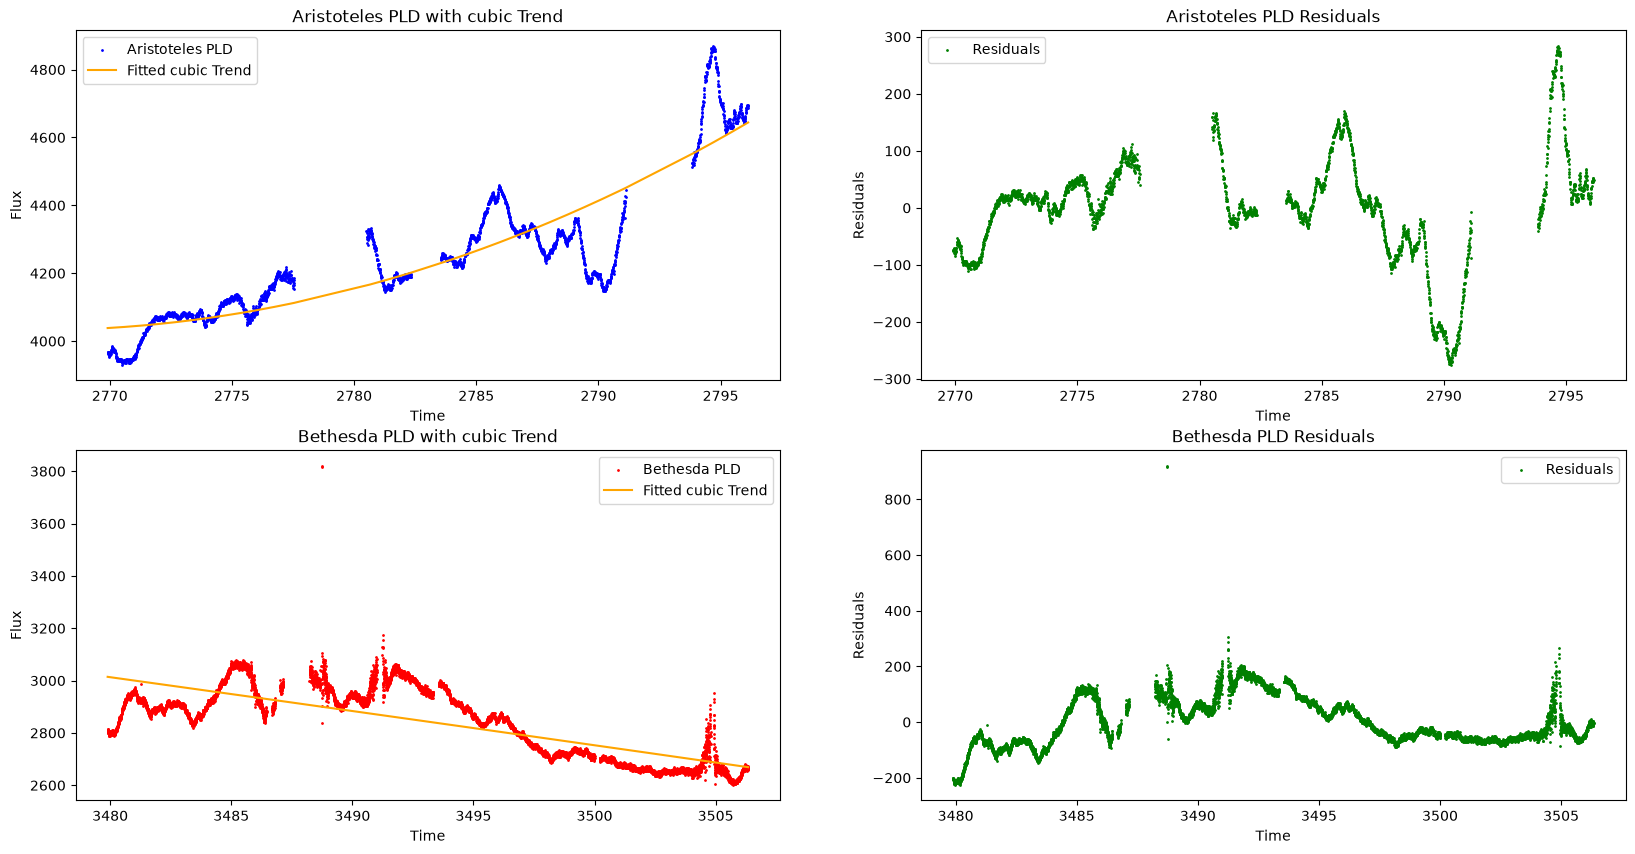

In [64]:
aristoteles_cubic_trend = identify_cubic_trend(lc_aristoteles_pld)
bethesda_cubic_trend = identify_cubic_trend(lc_bethesda_pld)

fig, ax = plt.subplots(2, 2, figsize=(20, 10))

ax[0, 0].scatter(lc_aristoteles_pld.time.value, lc_aristoteles_pld.flux.value, color='blue', s=1, label='Aristoteles PLD')
ax[0, 0].plot(lc_aristoteles_pld.time.value, aristoteles_cubic_trend["fitted_values"], color='orange', label='Fitted cubic Trend')
ax[0, 0].set_title('Aristoteles PLD with cubic Trend')
ax[0, 0].set_xlabel('Time')
ax[0, 0].set_ylabel('Flux')
ax[0, 0].legend()

ax[0, 1].scatter(lc_aristoteles_pld.time.value, aristoteles_cubic_trend["residuals"], color='green', s=1, label='Residuals')
ax[0, 1].set_title('Aristoteles PLD Residuals')
ax[0, 1].set_xlabel('Time')
ax[0, 1].set_ylabel('Residuals')
ax[0, 1].legend()

ax[1, 0].scatter(lc_bethesda_pld.time.value, lc_bethesda_pld.flux.value, color='red', s=1, label='Bethesda PLD')
ax[1, 0].plot(lc_bethesda_pld.time.value, bethesda_cubic_trend["fitted_values"], color='orange', label='Fitted cubic Trend')
ax[1, 0].set_title('Bethesda PLD with cubic Trend')
ax[1, 0].set_xlabel('Time')
ax[1, 0].set_ylabel('Flux')
ax[1, 0].legend()

ax[1, 1].scatter(lc_bethesda_pld.time.value, bethesda_cubic_trend["residuals"], color='green', s=1, label='Residuals')
ax[1, 1].set_title('Bethesda PLD Residuals')
ax[1, 1].set_xlabel('Time')
ax[1, 1].set_ylabel('Residuals')
ax[1, 1].legend()


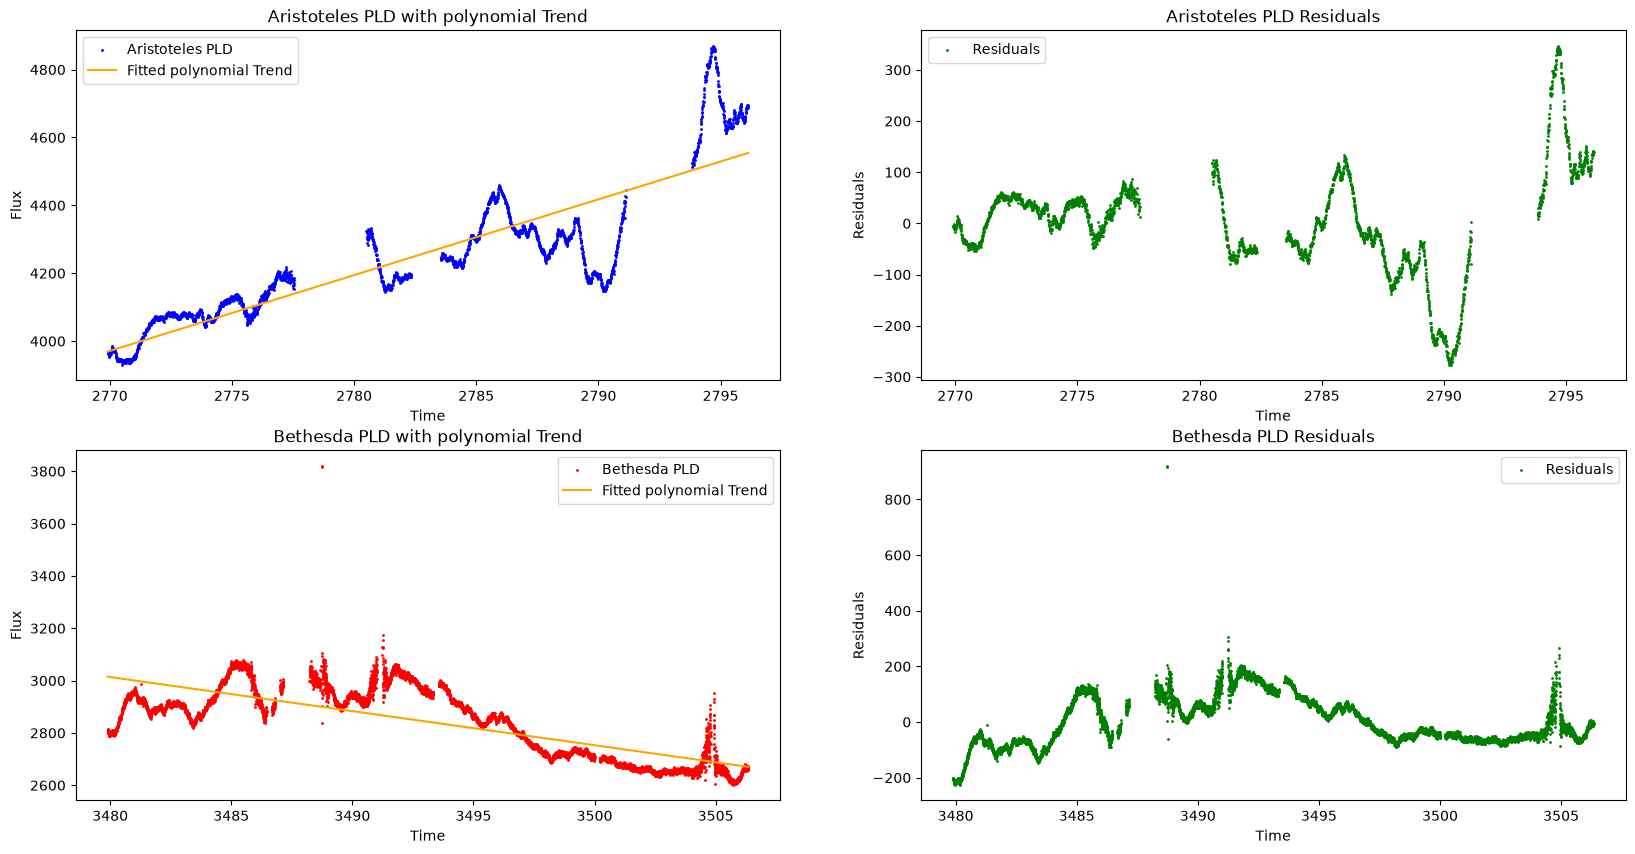

In [71]:
aristoteles_polynomial_trend = identify_polynomial_trend(lc_aristoteles_pld)
bethesda_polynomial_trend = identify_polynomial_trend(lc_bethesda_pld)

fig, ax = plt.subplots(2, 2, figsize=(20, 10))

ax[0, 0].scatter(lc_aristoteles_pld.time.value, lc_aristoteles_pld.flux.value, color='blue', s=1, label='Aristoteles PLD')
ax[0, 0].plot(lc_aristoteles_pld.time.value, aristoteles_polynomial_trend["fitted_values"], color='orange', label='Fitted polynomial Trend')
ax[0, 0].set_title('Aristoteles PLD with polynomial Trend')
ax[0, 0].set_xlabel('Time')
ax[0, 0].set_ylabel('Flux')
ax[0, 0].legend()

ax[0, 1].scatter(lc_aristoteles_pld.time.value, aristoteles_polynomial_trend["residuals"], color='green', s=1, label='Residuals')
ax[0, 1].set_title('Aristoteles PLD Residuals')
ax[0, 1].set_xlabel('Time')
ax[0, 1].set_ylabel('Residuals')
ax[0, 1].legend()

ax[1, 0].scatter(lc_bethesda_pld.time.value, lc_bethesda_pld.flux.value, color='red', s=1, label='Bethesda PLD')
ax[1, 0].plot(lc_bethesda_pld.time.value, bethesda_polynomial_trend["fitted_values"], color='orange', label='Fitted polynomial Trend')
ax[1, 0].set_title('Bethesda PLD with polynomial Trend')
ax[1, 0].set_xlabel('Time')
ax[1, 0].set_ylabel('Flux')
ax[1, 0].legend()

ax[1, 1].scatter(lc_bethesda_pld.time.value, bethesda_polynomial_trend["residuals"], color='green', s=1, label='Residuals')
ax[1, 1].set_title('Bethesda PLD Residuals')
ax[1, 1].set_xlabel('Time')
ax[1, 1].set_ylabel('Residuals')
ax[1, 1].legend()


Observational baseline: 26.214984 days
Number of observations: 2781
Typical sampling duration: 0.00694435 days (599.99 s)
Minimum searched period: 0.069443 days
Maximum searched period: 13.107492 days
Frequency resolution: 0.00381461 1/day

Best PDM candidate:
Period: 11.397819 days
Theta: 0.456211
Cycles observed: 2.30

Strongest independent PDM minima:
1: P = 11.397819 d, Theta = 0.456211, cycles = 2.30
2: P = 8.738328 d, Theta = 0.610855, cycles = 3.00
3: P = 7.281940 d, Theta = 0.714090, cycles = 3.60
4: P = 2.849455 d, Theta = 0.809517, cycles = 9.20
5: P = 5.698909 d, Theta = 0.830686, cycles = 4.60
6: P = 3.196949 d, Theta = 0.911287, cycles = 8.20
7: P = 4.519825 d, Theta = 0.927435, cycles = 5.80
8: P = 3.495331 d, Theta = 0.931974, cycles = 7.50
9: P = 3.744998 d, Theta = 0.940789, cycles = 7.00
10: P = 1.759395 d, Theta = 0.955474, cycles = 14.90


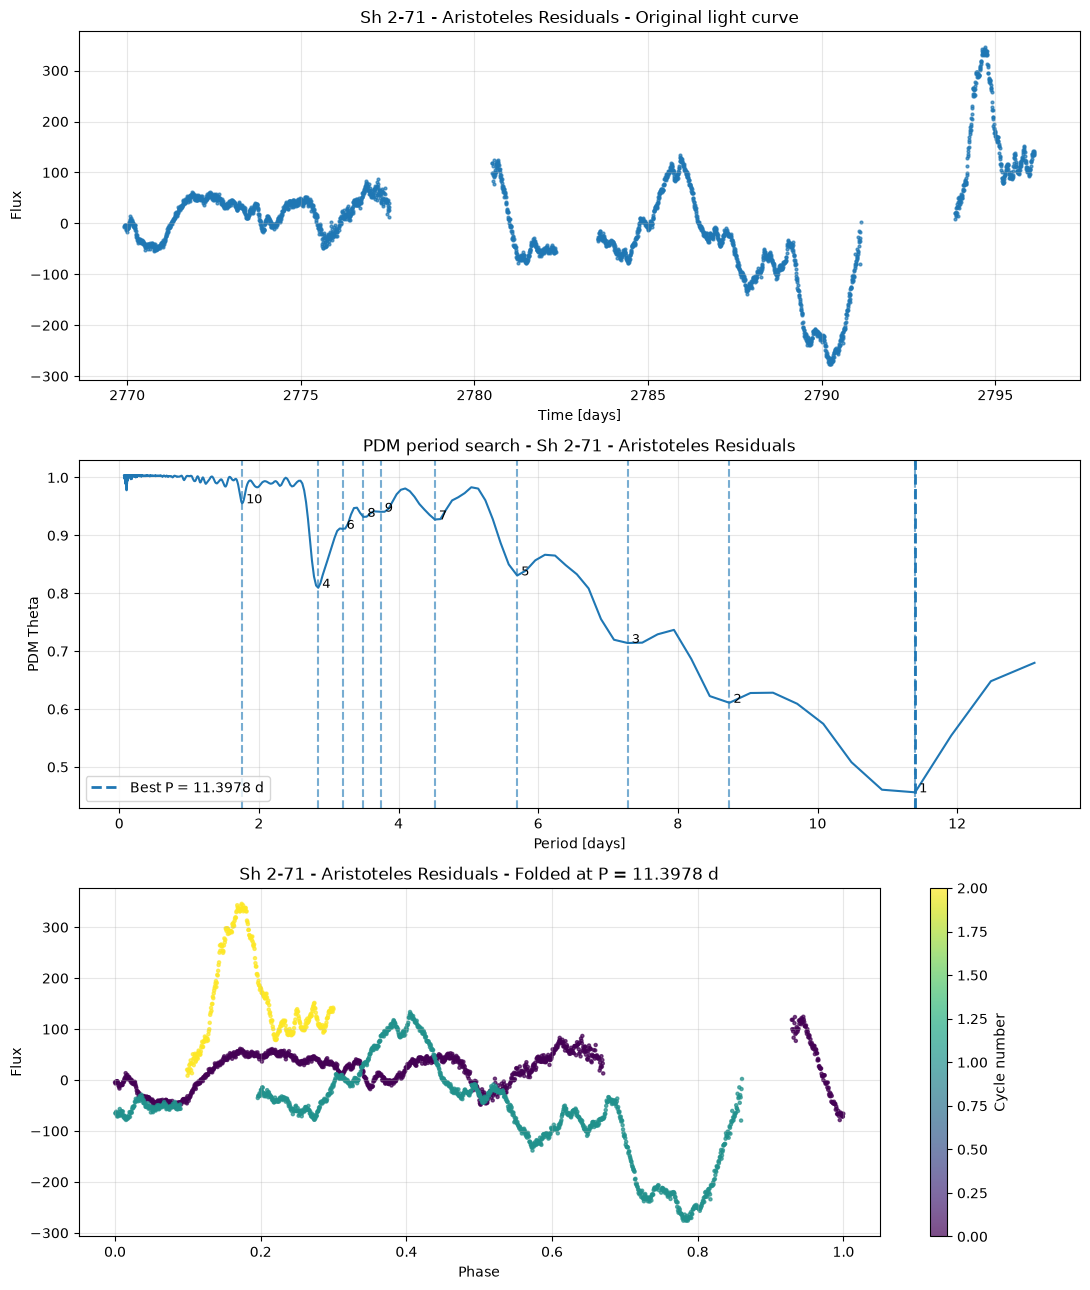

Observational baseline: 26.444691 days
Number of observations: 10399
Typical sampling duration: 0.00231484 days (200.00 s)
Minimum searched period: 0.023148 days
Maximum searched period: 13.222346 days
Frequency resolution: 0.00378148 1/day

Best PDM candidate:
Period: 7.345748 days
Theta: 0.822959
Cycles observed: 3.60

Strongest independent PDM minima:
1: P = 7.345748 d, Theta = 0.822959, cycles = 3.60
2: P = 6.449925 d, Theta = 0.899003, cycles = 4.10
3: P = 11.018621 d, Theta = 0.905531, cycles = 2.40
4: P = 8.530545 d, Theta = 0.909688, cycles = 3.10
5: P = 3.672874 d, Theta = 0.910112, cycles = 7.20
6: P = 9.794330 d, Theta = 0.914613, cycles = 2.70
7: P = 3.186107 d, Theta = 0.935523, cycles = 8.30
8: P = 6.010157 d, Theta = 0.946331, cycles = 4.40
9: P = 3.005079 d, Theta = 0.956114, cycles = 8.80
10: P = 5.509311 d, Theta = 0.960700, cycles = 4.80


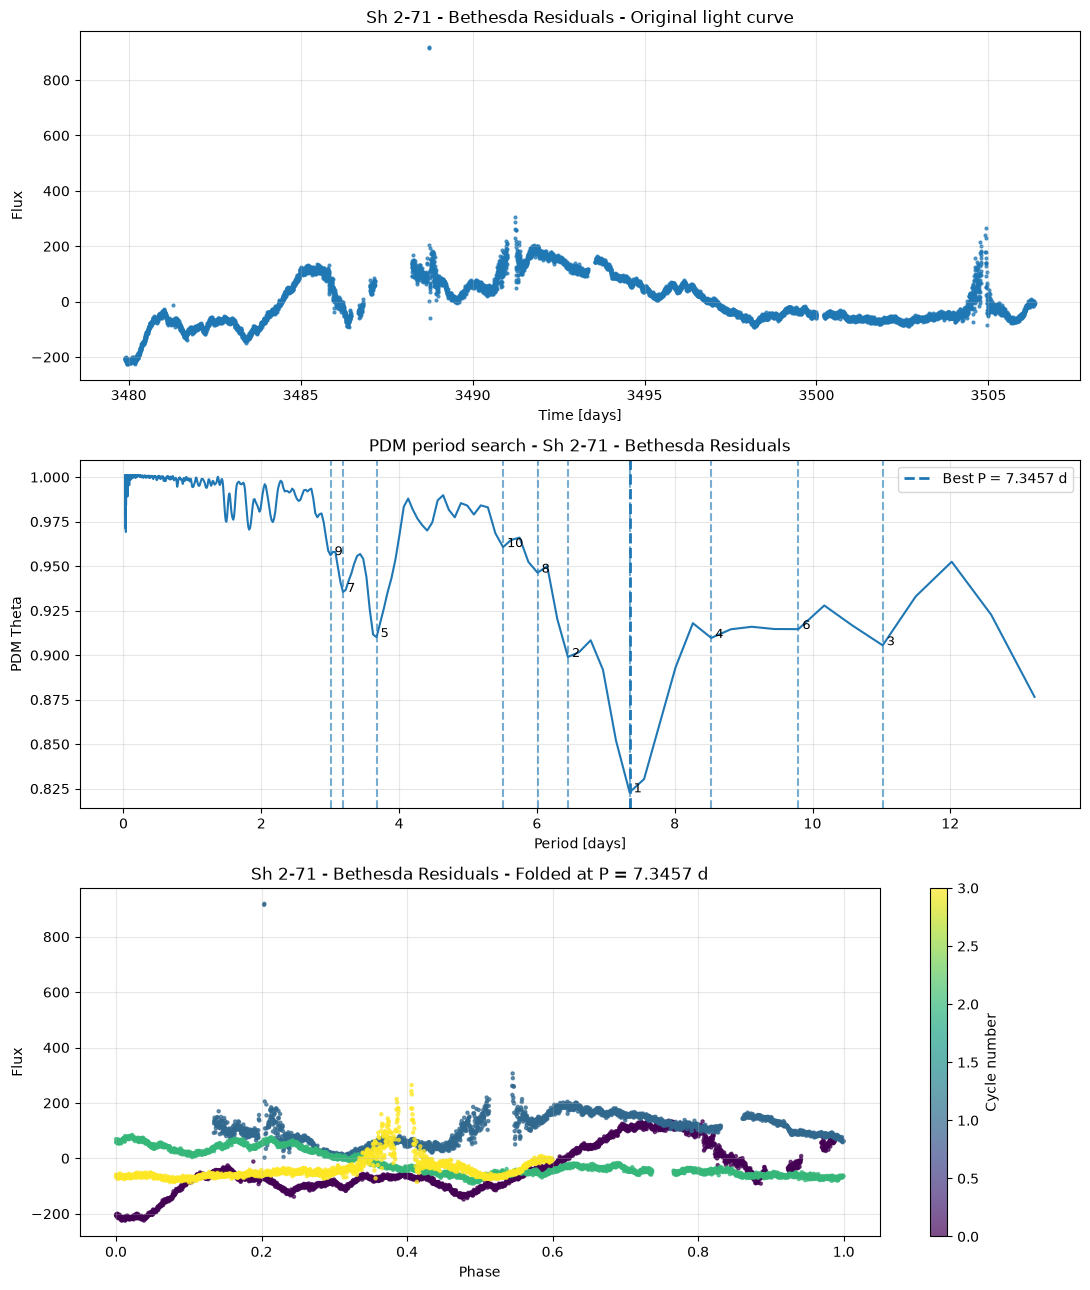

{'best_period': np.float64(7.345747511746796),
 'best_theta': np.float64(0.8229590802794776),
 'cycles_observed': np.float64(3.6),
 'period': array([ 0.02315039,  0.02315242,  0.02315444, ..., 12.02031411,
        12.59271002, 13.22234552], shape=(11404,)),
 'theta': array([1.00088091, 1.00088036, 1.00087956, ..., 0.95246764, 0.92273335,
        0.8765554 ], shape=(11404,)),
 'candidate_periods': array([ 7.34574751,  6.44992464, 11.01862127,  8.5305455 ,  3.67287376,
         9.79433002,  3.18610735,  6.01015706,  3.00507853,  5.50931063]),
 'candidate_theta': array([0.82295908, 0.89900349, 0.90553106, 0.90968751, 0.91011193,
        0.91461308, 0.93552307, 0.94633056, 0.9561136 , 0.96070015]),
 'baseline': np.float64(26.44469104228847),
 'sampling_duration': np.float64(0.002314842126907024),
 'min_period': np.float64(0.02314842126907024),
 'max_period': np.float64(13.222345521144234)}

In [67]:
process_pdm(lc_aristoteles_pld.time.value, aristoteles_polynomial_trend["residuals"], n_bins=10, n_candidates=10, title="Sh 2-71 - Aristoteles Residuals")
process_pdm(lc_bethesda_pld.time.value, bethesda_polynomial_trend["residuals"], n_bins=10, n_candidates=10, title="Sh 2-71 - Bethesda Residuals")